<a href="https://colab.research.google.com/github/iamnaymur/ml_meta_learning/blob/main/ADS_B_Few_Shot_Method_Comparison_7_Features.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Step 1 — Load source trajectories for a fresh experiment
from google.colab import drive
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import torch

drive.mount("/content/drive")

SOURCE_PATH = Path(
    "/content/drive/MyDrive/Machine learning/airspace_dataset.parquet"
)

RUN_DIR = SOURCE_PATH.parent / (
    "TabularResNet_FromScratch_"
    + datetime.now().strftime("%Y%m%d_%H%M%S_%f")
)
RUN_DIR.mkdir(parents=True, exist_ok=False)

df_airspace = pd.read_parquet(SOURCE_PATH)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

TRAINING_CONFIG = {
    "model_seeds": [42, 101, 202],
    "training_episode_seed": 2026,
    "training_episodes": 300,
    "window_size": 30,
    "num_features": 7,
    "embedding_dim": 32,
    "n_way": 3,
    "n_shot": 5,
    "n_query": 5,
    "learning_rate": 0.001,
}

display(pd.DataFrame({
    "Column": df_airspace.columns,
    "Data type": df_airspace.dtypes.astype(str).to_numpy()
}))
display(df_airspace.head(3))
print(f"Rows: {len(df_airspace):,} | Device: {DEVICE}")

Mounted at /content/drive


,Column,Data type
0,timestamp,"datetime64[ms, UTC]"
1,altitude,float64
2,callsign,object
3,geoaltitude,float64
4,groundspeed,float64
5,icao24,object
6,latitude,float64
7,longitude,float64
8,squawk,object
9,track,float64


,timestamp,altitude,callsign,geoaltitude,groundspeed,icao24,latitude,longitude,squawk,track,vertical_rate,flight_id
0,2017-03-14 20:34:57+00:00,24725.0,AF526KB,25550.0,429.786785,392ae6,48.115631,2.063919,1000,183.460183,1408.0,AF526KB_4117
1,2017-03-14 20:34:58+00:00,24750.0,AF526KB,25550.0,430.784957,392ae6,48.115631,2.063919,1000,183.460183,1408.0,AF526KB_4117
2,2017-03-14 20:34:59+00:00,24750.0,AF526KB,25550.0,430.784957,392ae6,48.115631,2.063919,1000,183.460183,1408.0,AF526KB_4117


Rows: 13,338,847 | Device: cpu


In [ ]:
# Step 2 — Aircraft-disjoint training, validation and test splits
from sklearn.model_selection import GroupShuffleSplit

assert df_airspace["icao24"].notna().all()

aircraft_table = pd.DataFrame({
    "icao24": df_airspace["icao24"].unique()
})

# Preserve the original aircraft ordering and splitting method.
split1 = GroupShuffleSplit(
    n_splits=1, train_size=0.70, random_state=42
)
train_idx, temp_idx = next(
    split1.split(aircraft_table, groups=aircraft_table["icao24"])
)

train_aircraft = aircraft_table.iloc[train_idx]["icao24"].to_numpy()
temp_table = aircraft_table.iloc[temp_idx].reset_index(drop=True)

split2 = GroupShuffleSplit(
    n_splits=1, train_size=0.50, random_state=42
)
val_idx, test_idx = next(
    split2.split(temp_table, groups=temp_table["icao24"])
)

val_aircraft = temp_table.iloc[val_idx]["icao24"].to_numpy()
test_aircraft = temp_table.iloc[test_idx]["icao24"].to_numpy()

train_ids = set(train_aircraft)
val_ids = set(val_aircraft)
test_ids = set(test_aircraft)

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)
assert train_ids | val_ids | test_ids == set(aircraft_table["icao24"])

split_map = {
    **dict.fromkeys(train_aircraft, "Train"),
    **dict.fromkeys(val_aircraft, "Validation"),
    **dict.fromkeys(test_aircraft, "Test"),
}

aircraft_splits = aircraft_table.copy()
aircraft_splits["Partition"] = aircraft_splits["icao24"].map(split_map)
aircraft_splits.to_csv(RUN_DIR / "aircraft_splits.csv", index=False)

split_summary = (
    aircraft_splits.groupby("Partition")
    .size()
    .reindex(["Train", "Validation", "Test"])
    .rename("Aircraft")
    .to_frame()
)
split_summary["Percentage (%)"] = (
    split_summary["Aircraft"] / len(aircraft_table) * 100
).round(2)

display(split_summary)

,Aircraft,Percentage (%)
Partition,,
Train,2053,69.97
Validation,440,15.00
Test,441,15.03


In [ ]:
# Step 3 — Build flight metadata and candidate window index
WINDOW_SIZE = 30
WINDOW_STRIDE = 30
HISTORY = 20

assert df_airspace[["flight_id", "timestamp"]].notna().all().all()
assert (
    df_airspace.groupby("flight_id")["icao24"].nunique() == 1
).all()

# A small source table avoids copying all trajectory features.
index_source = (
    df_airspace[["flight_id", "icao24", "timestamp"]]
    .sort_values(["flight_id", "timestamp"])
    .reset_index(drop=True)
)
index_source["partition"] = index_source["icao24"].map(split_map)
assert index_source["partition"].notna().all()

flight_info = (
    index_source.groupby("flight_id", sort=False)
    .agg(
        icao24=("icao24", "first"),
        partition=("partition", "first"),
        n_observations=("timestamp", "size"),
        flight_start=("timestamp", "first"),
        flight_end=("timestamp", "last")
    )
    .reset_index()
)

flight_info["flight_start_row"] = (
    flight_info["n_observations"].shift(fill_value=0).cumsum()
).astype(np.int64)

flight_info["n_windows"] = np.maximum(
    0,
    (flight_info["n_observations"] - HISTORY - WINDOW_SIZE)
    // WINDOW_STRIDE + 1
).astype(int)

records = []
for flight in flight_info.itertuples(index=False):
    for window_number in range(flight.n_windows):
        start = (
            flight.flight_start_row
            + HISTORY
            + window_number * WINDOW_STRIDE
        )
        records.append({
            "flight_id": flight.flight_id,
            "icao24": flight.icao24,
            "partition": flight.partition,
            "start_row": int(start),
            "end_row_exclusive": int(start + WINDOW_SIZE),
            "window_number": window_number
        })

window_index_df = pd.DataFrame(records)

# Verify that each window stays within its flight.
starts = window_index_df["start_row"].to_numpy()
ends = window_index_df["end_row_exclusive"].to_numpy() - 1

assert np.array_equal(
    index_source["flight_id"].to_numpy()[starts],
    window_index_df["flight_id"].to_numpy()
)
assert np.array_equal(
    index_source["flight_id"].to_numpy()[starts],
    index_source["flight_id"].to_numpy()[ends]
)

window_summary = (
    window_index_df.groupby("partition")
    .agg(
        Aircraft=("icao24", "nunique"),
        Flights=("flight_id", "nunique"),
        Candidate_windows=("flight_id", "size")
    )
    .reindex(["Train", "Validation", "Test"])
)

display(window_summary)

,Aircraft,Flights,Candidate_windows
partition,,,
Train,2053,10870,295882
Validation,440,2601,67859
Test,441,2340,62738


In [ ]:
# Step 4 — Define speed features and check one training window
SPEED_FEATURES = [
    "groundspeed",
    "speed_20s_knots",
    "speed_error_10s",
    "speed_error_20s"
]

FEATURE_NAMES_7 = SPEED_FEATURES + [
    "signed_speed_difference",
    "reported_speed_change",
    "derived_speed_change"
]


def engineer_complete_flight(flight_data):
    flight = (
        flight_data.sort_values("timestamp")
        .copy()
        .reset_index(drop=True)
    )

    lat = np.radians(flight["latitude"].to_numpy(dtype=np.float64))
    lon = np.radians(flight["longitude"].to_numpy(dtype=np.float64))

    for interval in [10, 20]:
        dlat = lat[interval:] - lat[:-interval]
        dlon = lon[interval:] - lon[:-interval]

        a = (
            np.sin(dlat / 2) ** 2
            + np.cos(lat[:-interval]) * np.cos(lat[interval:])
            * np.sin(dlon / 2) ** 2
        )
        distance_m = (
            2 * 6371000.0 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
        )

        elapsed = (
            flight["timestamp"].diff(interval)
            .dt.total_seconds().to_numpy()[interval:]
        )

        speed = np.full(len(flight), np.nan)
        speed[interval:] = np.divide(
            distance_m * 1.94384449,
            elapsed,
            out=np.full(len(distance_m), np.nan),
            where=elapsed > 0
        )
        flight[f"speed_{interval}s_knots"] = speed

    return flight


def extract_four_features(engineered_flight, start):
    window = engineered_flight.iloc[start:start + WINDOW_SIZE]

    reported = window["groundspeed"].to_numpy(dtype=np.float32)
    derived10 = window["speed_10s_knots"].to_numpy(dtype=np.float32)
    derived20 = window["speed_20s_knots"].to_numpy(dtype=np.float32)

    features = np.column_stack([
        reported,
        derived20,
        np.abs(reported - derived10),
        np.abs(reported - derived20)
    ]).astype(np.float32)

    assert features.shape == (WINDOW_SIZE, 4)
    assert np.isfinite(features).all()
    return features


def build_7_features(X):
    # X contains unscaled windows: (number of windows, 30, 4).
    reported = X[:, :, 0]
    derived = X[:, :, 1]

    return np.concatenate([
        X,
        (reported - derived)[:, :, None],
        np.diff(
            reported, axis=1, prepend=reported[:, :1]
        )[:, :, None],
        np.diff(
            derived, axis=1, prepend=derived[:, :1]
        )[:, :, None]
    ], axis=2).astype(np.float32)


# Check the functions on one training flight only.
example_flight_id = flight_info.loc[
    (flight_info["partition"] == "Train")
    & (flight_info["n_windows"] > 0),
    "flight_id"
].iloc[0]

example_flight = df_airspace.loc[
    df_airspace["flight_id"] == example_flight_id,
    ["timestamp", "latitude", "longitude", "groundspeed"]
]

example_engineered = engineer_complete_flight(example_flight)
example_raw4 = extract_four_features(example_engineered, HISTORY)
example_raw7 = build_7_features(example_raw4[None, ...])[0]

assert example_raw7.shape == (30, 7)
assert np.isfinite(example_raw7).all()

display(pd.DataFrame(example_raw7, columns=FEATURE_NAMES_7).head())

,groundspeed,speed_20s_knots,speed_error_10s,speed_error_20s,signed_speed_difference,reported_speed_change,derived_speed_change
0,198.59993,128.487106,8.991455,70.112823,70.112823,0.0,0.000000
1,198.59993,137.144882,12.290436,61.455048,61.455048,0.0,8.657776
2,198.59993,145.802948,15.588165,52.796982,52.796982,0.0,8.658066
3,198.59993,154.461227,10.069611,44.138702,44.138702,0.0,8.658279
4,198.59993,167.658981,5.524582,30.940948,30.940948,0.0,13.197754


In [ ]:
# Step 5 — Define the original attack simulation rules
EARTH_RADIUS_M = 6371000.0

PATH_ATTACK_INTENSITIES = {
    "weak": 100.0,
    "moderate": 300.0,
    "strong": 500.0
}
DRIFT_CONDITIONS = [-20, -10, -5, 5, 10, 20]

CLASS_NAMES = ["Normal", "Path Modification", "Velocity Drift"]


def attack_profile(attack_length=30, recovery_length=20):
    if attack_length < 2 or recovery_length < 2:
        raise ValueError("Growth and recovery lengths must be at least 2.")

    t = np.linspace(0, 1, attack_length)
    growth = 3 * t**2 - 2 * t**3

    t = np.linspace(0, 1, recovery_length)
    recovery = 1 - (3 * t**2 - 2 * t**3)

    return np.concatenate([growth, recovery])


def simulate_path_modification(
    flight_df, start_index, intensity="moderate",
    attack_length=30, recovery_length=20, seed=42
):
    modified = (
        flight_df.sort_values("timestamp")
        .copy(deep=True).reset_index(drop=True)
    )

    end = start_index + attack_length + recovery_length
    if start_index < 0 or end > len(modified):
        raise ValueError("Attack exceeds flight boundaries.")
    if intensity not in PATH_ATTACK_INTENSITIES:
        raise ValueError("Unknown path intensity.")

    displacement = (
        attack_profile(attack_length, recovery_length)
        * PATH_ATTACK_INTENSITIES[intensity]
    )
    direction = np.random.default_rng(seed).uniform(0, 2 * np.pi)

    east_offset = displacement * np.sin(direction)
    north_offset = displacement * np.cos(direction)

    indices = modified.index[start_index:end]
    lat = modified.loc[indices, "latitude"].to_numpy(dtype=np.float64)
    lon = modified.loc[indices, "longitude"].to_numpy(dtype=np.float64)

    modified.loc[indices, "latitude"] = lat + (
        north_offset / EARTH_RADIUS_M
    ) * (180.0 / np.pi)

    modified.loc[indices, "longitude"] = lon + (
        east_offset / (EARTH_RADIUS_M * np.cos(np.radians(lat)))
    ) * (180.0 / np.pi)

    return modified, {
        "attack_type": "path_modification",
        "label": 1,
        "intensity": intensity,
        "max_displacement_m": PATH_ATTACK_INTENSITIES[intensity],
        "direction_degrees": float(np.degrees(direction)),
        "start_index": int(start_index),
        "end_index_exclusive": int(end),
        "seed": int(seed)
    }


def simulate_velocity_drift(
    flight_df, start_index, max_drift_knots=20.0,
    attack_length=30, recovery_length=20
):
    modified = (
        flight_df.sort_values("timestamp")
        .copy(deep=True).reset_index(drop=True)
    )

    end = start_index + attack_length + recovery_length
    if start_index < 0 or end > len(modified):
        raise ValueError("Attack exceeds flight boundaries.")

    offset = (
        attack_profile(attack_length, recovery_length)
        * max_drift_knots
    )
    indices = modified.index[start_index:end]
    modified.loc[indices, "groundspeed"] += offset

    return modified, {
        "attack_type": "velocity_drift",
        "label": 2,
        "drift_knots": float(max_drift_knots),
        "start_index": int(start_index),
        "end_index_exclusive": int(end)
    }


print("Path-modification and velocity-drift functions are ready.")

Path-modification and velocity-drift functions are ready.


In [ ]:
# Step 6 — Verify simulations on one training flight
check_start = 40

check_flight_id = flight_info.loc[
    (flight_info["partition"] == "Train")
    & (flight_info["n_observations"] >= check_start + 50),
    "flight_id"
].iloc[0]

original = (
    df_airspace.loc[
        df_airspace["flight_id"] == check_flight_id,
        ["timestamp", "latitude", "longitude", "groundspeed"]
    ]
    .sort_values("timestamp")
    .reset_index(drop=True)
)
original_snapshot = original.copy(deep=True)

path_flight, _ = simulate_path_modification(
    original, check_start, intensity="moderate", seed=42
)
positive_flight, _ = simulate_velocity_drift(
    original, check_start, max_drift_knots=10
)
negative_flight, _ = simulate_velocity_drift(
    original, check_start, max_drift_knots=-10
)

# Path attack changes position but preserves reported speed.
np.testing.assert_array_equal(
    path_flight["groundspeed"], original["groundspeed"]
)
assert np.any(
    path_flight[["latitude", "longitude"]].to_numpy()
    != original[["latitude", "longitude"]].to_numpy()
)

# Speed attacks preserve position and apply the requested profile.
expected_offset = np.zeros(len(original))
expected_offset[check_start:check_start + 50] = attack_profile() * 10

for attacked, sign in [(positive_flight, 1), (negative_flight, -1)]:
    np.testing.assert_array_equal(
        attacked[["latitude", "longitude"]],
        original[["latitude", "longitude"]]
    )
    np.testing.assert_allclose(
        attacked["groundspeed"] - original["groundspeed"],
        sign * expected_offset,
        rtol=0, atol=1e-8
    )

# Confirm that the original flight was not modified.
pd.testing.assert_frame_equal(original, original_snapshot)

check_rows = []
simulation_check_features = {}

for name, flight in {
    "Normal": original,
    "Path modification — moderate": path_flight,
    "Velocity drift +10 knots": positive_flight,
    "Velocity drift -10 knots": negative_flight
}.items():
    engineered = engineer_complete_flight(flight)
    raw4 = extract_four_features(engineered, check_start)
    raw7 = build_7_features(raw4[None, ...])[0]

    assert raw7.shape == (30, 7)
    assert np.isfinite(raw7).all()

    simulation_check_features[name] = raw7
    check_rows.append({
        "Example": name,
        "Window shape": str(raw7.shape),
        "All values finite": bool(np.isfinite(raw7).all()),
        "Maximum absolute speed offset (knots)": float(
            np.abs(flight["groundspeed"] - original["groundspeed"]).max()
        )
    })

for name in list(simulation_check_features)[1:]:
    assert not np.allclose(
        simulation_check_features[name],
        simulation_check_features["Normal"]
    )

display(pd.DataFrame(check_rows).round(2))

,Example,Window shape,All values finite,Maximum absolute speed offset (knots)
0,Normal,"(30, 7)",True,0.0
1,Path modification — moderate,"(30, 7)",True,0.0
2,Velocity drift +10 knots,"(30, 7)",True,10.0
3,Velocity drift -10 knots,"(30, 7)",True,10.0


In [ ]:
# Step 7 — Select and label the training-window plan
flight_lengths = flight_info.set_index("flight_id")["n_observations"]
flight_starts = flight_info.set_index("flight_id")["flight_start_row"]

train_pool = window_index_df.loc[
    window_index_df["partition"] == "Train"
].copy()

train_pool["local_start"] = (
    train_pool["start_row"]
    - train_pool["flight_id"].map(flight_starts)
)
train_pool["flight_length"] = (
    train_pool["flight_id"].map(flight_lengths)
)

# Require history plus space for 30 growth + 20 recovery observations.
eligible_pool = train_pool.loc[
    (train_pool["local_start"] >= HISTORY)
    & (train_pool["local_start"] + 50 <= train_pool["flight_length"])
].copy()

assert eligible_pool["icao24"].nunique() >= 1500

# Original selection: 1,000 aircraft for Normal and Path Modification.
rng_large = np.random.default_rng(42)
selected_ids = rng_large.choice(
    eligible_pool["icao24"].unique(), size=1000, replace=False
)

large_train_plan = (
    eligible_pool[eligible_pool["icao24"].isin(selected_ids)]
    .groupby("icao24", group_keys=False)
    .sample(n=1, random_state=42)
    .sample(frac=1, random_state=42)
    .reset_index(drop=True)
)

large_train_plan["label"] = 0
large_train_plan.loc[500:, "label"] = 1
large_train_plan["attack_intensity"] = "none"

path_rows = large_train_plan.index[large_train_plan["label"] == 1]
large_train_plan.loc[path_rows, "attack_intensity"] = [
    ["weak", "moderate", "strong"][i % 3]
    for i in range(len(path_rows))
]

# Select another 500 aircraft for Velocity Drift.
unused = eligible_pool.copy()
unused["icao24"] = unused["icao24"].astype(str)
unused = unused.loc[
    ~unused["icao24"].isin(
        set(large_train_plan["icao24"].astype(str))
    )
].copy()

rng_drift = np.random.default_rng(2026)
drift_ids = rng_drift.choice(
    np.sort(unused["icao24"].unique()), size=500, replace=False
)

drift_train_plan = (
    unused[unused["icao24"].isin(drift_ids)]
    .groupby("icao24", group_keys=False)
    .sample(n=1, random_state=2026)
    .sample(frac=1, random_state=2026)
    .reset_index(drop=True)
)

drift_train_plan["label"] = 2
drift_train_plan["attack_intensity"] = "none"
drift_train_plan["drift_knots"] = rng_drift.permutation(
    np.resize(DRIFT_CONDITIONS, 500)
)

training_plan = pd.concat(
    [large_train_plan, drift_train_plan], ignore_index=True
)
training_plan["icao24"] = training_plan["icao24"].astype(str)

assert len(training_plan) == 1500
assert training_plan["icao24"].is_unique
assert training_plan["label"].value_counts().to_dict() == {
    0: 500, 1: 500, 2: 500
}
assert set(training_plan["icao24"]).isdisjoint(
    set(map(str, val_aircraft)) | set(map(str, test_aircraft))
)

training_plan.to_csv(RUN_DIR / "training_window_plan.csv", index=False)

display(
    training_plan.groupby("label")
    .agg(
        Windows=("flight_id", "size"),
        Aircraft=("icao24", "nunique")
    )
    .rename(index=dict(enumerate(CLASS_NAMES)))
)

,Windows,Aircraft
label,,
Normal,500,500
Path Modification,500,500
Velocity Drift,500,500


In [ ]:
# Step 8: Generate the training windows and their seven features

def extract_four_features(engineered_flight, start):
    window = engineered_flight.iloc[start:start + WINDOW_SIZE]

    reported = window["groundspeed"].to_numpy(dtype=np.float64)
    derived10 = window["speed_10s_knots"].to_numpy(dtype=np.float64)
    derived20 = window["speed_20s_knots"].to_numpy(dtype=np.float64)

    features = np.column_stack([
        reported,
        derived20,
        np.abs(reported - derived10),
        np.abs(reported - derived20),
    ]).astype(np.float32)

    assert features.shape == (WINDOW_SIZE, 4)
    assert np.isfinite(features).all()
    return features


needed_columns = [
    "flight_id", "timestamp", "latitude", "longitude", "groundspeed"
]

training_source = df_airspace.loc[
    df_airspace["flight_id"].isin(training_plan["flight_id"]),
    needed_columns,
].copy()

training_flights = {
    flight_id: group.sort_values("timestamp").reset_index(drop=True)
    for flight_id, group in training_source.groupby("flight_id", sort=False)
}
del training_source

training_windows = []
training_records = []

for i, row in training_plan.reset_index(drop=True).iterrows():
    original = training_flights[row["flight_id"]]
    start = int(row["local_start"])
    label = int(row["label"])

    modified = original
    attack_seed = None

    if label == 1:
        attack_seed = 42 + i
        modified, _ = simulate_path_modification(
            flight_df=original,
            start_index=start,
            intensity=row["attack_intensity"],
            attack_length=30,
            recovery_length=20,
            seed=attack_seed,
        )

    elif label == 2:
        modified, _ = simulate_velocity_drift(
            flight_df=original,
            start_index=start,
            max_drift_knots=float(row["drift_knots"]),
            attack_length=30,
            recovery_length=20,
        )

        actual_drift = (
            modified["groundspeed"].iloc[start + WINDOW_SIZE - 1]
            - original["groundspeed"].iloc[start + WINDOW_SIZE - 1]
        )
        assert np.isclose(actual_drift, row["drift_knots"], atol=1e-5)

    engineered = engineer_complete_flight(modified)
    training_windows.append(extract_four_features(engineered, start))

    training_records.append({
        "icao24": str(row["icao24"]),
        "flight_id": row["flight_id"],
        "partition": "Train",
        "local_start": start,
        "label": label,
        "intensity": row["attack_intensity"],
        "drift_knots": float(row["drift_knots"]) if label == 2 else 0.0,
        "attack_seed": attack_seed,
    })

X_train_3_raw = np.stack(training_windows)
X_train_7_raw = build_7_features(X_train_3_raw)
train_metadata_3 = pd.DataFrame(training_records)
y_train_3 = train_metadata_3["label"].to_numpy(dtype=np.int64)

assert X_train_7_raw.shape == (1500, 30, 7)
assert np.isfinite(X_train_7_raw).all()
assert train_metadata_3["icao24"].is_unique
assert np.array_equal(np.bincount(y_train_3), [500, 500, 500])

del training_flights, training_windows

display(pd.DataFrame({
    "Class": CLASS_NAMES,
    "Windows": np.bincount(y_train_3),
    "Window shape": [X_train_7_raw.shape[1:]] * 3,
    "All values finite": [
        bool(np.isfinite(X_train_7_raw[y_train_3 == label]).all())
        for label in range(3)
    ],
}))

,Class,Windows,Window shape,All values finite
0,Normal,500,"(30, 7)",True
1,Path Modification,500,"(30, 7)",True
2,Velocity Drift,500,"(30, 7)",True


In [ ]:
# Step 9: Fit the scaler on training data only

from sklearn.preprocessing import StandardScaler
import joblib

assert X_train_7_raw.shape == (1500, 30, 7)
assert np.isfinite(X_train_7_raw).all()

scaler_7 = StandardScaler()

# Temporarily combine windows into rows to scale each feature.
training_rows = X_train_7_raw.reshape(-1, 7)

X_train_7 = scaler_7.fit_transform(training_rows).reshape(
    X_train_7_raw.shape
).astype(np.float32)

assert np.isfinite(X_train_7).all()

joblib.dump(scaler_7, RUN_DIR / "scaler_7.joblib")

display(pd.DataFrame({
    "Feature": FEATURE_NAMES_7,
    "Mean after scaling": X_train_7.mean(axis=(0, 1)),
    "SD after scaling": X_train_7.std(axis=(0, 1)),
}).round(4))

,Feature,Mean after scaling,SD after scaling
0,groundspeed,-0.0,1.0000
1,speed_20s_knots,-0.0,1.0000
2,speed_error_10s,0.0,1.0000
3,speed_error_20s,-0.0,1.0000
4,signed_speed_difference,0.0,1.0000
5,reported_speed_change,0.0,0.9999
6,derived_speed_change,-0.0,1.0000


In [ ]:
# Step 10: Select, generate, and scale the validation windows (150 aircraft)
val_pool = window_index_df.loc[window_index_df["partition"] == "Validation"].copy()
val_pool["local_start"] = val_pool["start_row"] - val_pool["flight_id"].map(flight_starts)
val_pool["flight_length"] = val_pool["flight_id"].map(flight_lengths)

eligible_val_pool = val_pool.loc[
    (val_pool["local_start"] >= HISTORY)
    & (val_pool["local_start"] + 50 <= val_pool["flight_length"])
].copy()

# 100 aircraft for Normal (50) and Path Modification (50)
rng_val_large = np.random.default_rng(42)
val_selected_ids = rng_val_large.choice(
    eligible_val_pool["icao24"].unique(), size=100, replace=False
)

large_val_plan = (
    eligible_val_pool[eligible_val_pool["icao24"].isin(val_selected_ids)]
    .groupby("icao24", group_keys=False)
    .sample(n=1, random_state=42)
    .sample(frac=1, random_state=42)
    .reset_index(drop=True)
)
large_val_plan["label"] = 0
large_val_plan.loc[50:, "label"] = 1
large_val_plan["attack_intensity"] = "none"

val_path_rows = large_val_plan.index[large_val_plan["label"] == 1]
large_val_plan.loc[val_path_rows, "attack_intensity"] = [
    ["weak", "moderate", "strong"][i % 3] for i in range(len(val_path_rows))
]

# 50 distinct aircraft for Velocity Drift
unused_val = eligible_val_pool.copy()
unused_val["icao24"] = unused_val["icao24"].astype(str)
unused_val = unused_val.loc[
    ~unused_val["icao24"].isin(set(large_val_plan["icao24"].astype(str)))
].copy()

rng_val_drift = np.random.default_rng(2026)
val_drift_ids = rng_val_drift.choice(
    np.sort(unused_val["icao24"].unique()), size=50, replace=False
)

drift_val_plan = (
    unused_val[unused_val["icao24"].isin(val_drift_ids)]
    .groupby("icao24", group_keys=False)
    .sample(n=1, random_state=2026)
    .sample(frac=1, random_state=2026)
    .reset_index(drop=True)
)
drift_val_plan["label"] = 2
drift_val_plan["attack_intensity"] = "none"
drift_val_plan["drift_knots"] = rng_val_drift.permutation(
    np.resize(DRIFT_CONDITIONS, 50)
)

validation_plan = pd.concat([large_val_plan, drift_val_plan], ignore_index=True)
validation_plan["icao24"] = validation_plan["icao24"].astype(str)

val_source = df_airspace.loc[
    df_airspace["flight_id"].isin(validation_plan["flight_id"]), needed_columns
].copy()
val_flights = {
    fid: grp.sort_values("timestamp").reset_index(drop=True)
    for fid, grp in val_source.groupby("flight_id", sort=False)
}
del val_source

val_windows, val_records = [], []
# Store clean source versions and all 6 drift variants for Step 6 & Step 8 evaluations
X_original_paired_raw4, paired_idx = [], []
drift_variants_raw4 = {k: [] for k in DRIFT_CONDITIONS}

for i, row in validation_plan.reset_index(drop=True).iterrows():
    original = val_flights[row["flight_id"]]
    start = int(row["local_start"])
    label = int(row["label"])
    modified = original
    attack_seed = None

    # Save clean features for attacked aircraft (Paired Clean-vs-Attacked check)
    if label in [1, 2]:
        paired_idx.append(i)
        eng_clean = engineer_complete_flight(original)
        X_original_paired_raw4.append(extract_four_features(eng_clean, start))

    if label == 1:
        attack_seed = 42 + i
        modified, _ = simulate_path_modification(
            original, start, intensity=row["attack_intensity"],
            attack_length=30, recovery_length=20, seed=attack_seed
        )
    elif label == 2:
        modified, _ = simulate_velocity_drift(
            original, start, max_drift_knots=float(row["drift_knots"]),
            attack_length=30, recovery_length=20
        )
        # Also build all 6 drift variants for this drift aircraft (Step 6 evaluation)
        for k in DRIFT_CONDITIONS:
            mod_k, _ = simulate_velocity_drift(
                original, start, max_drift_knots=float(k),
                attack_length=30, recovery_length=20
            )
            eng_k = engineer_complete_flight(mod_k)
            drift_variants_raw4[k].append(extract_four_features(eng_k, start))

    engineered = engineer_complete_flight(modified)
    val_windows.append(extract_four_features(engineered, start))
    val_records.append({
        "icao24": str(row["icao24"]),
        "flight_id": row["flight_id"],
        "partition": "Validation",
        "local_start": start,
        "label": label,
        "intensity": row["attack_intensity"],
        "drift_knots": float(row["drift_knots"]) if label == 2 else 0.0,
        "attack_seed": attack_seed,
    })

X_val_3_raw = np.stack(val_windows)
X_val_7_raw = build_7_features(X_val_3_raw)
X_val_7 = scaler_7.transform(X_val_7_raw.reshape(-1, 7)).reshape(X_val_7_raw.shape).astype(np.float32)

val_metadata_3 = pd.DataFrame(val_records)
y_val_3 = val_metadata_3["label"].to_numpy(dtype=np.int64)

# Scale paired clean windows and 6 drift variants using training scaler
paired_idx = np.array(paired_idx, dtype=int)
X_original_paired_7 = build_7_features(np.stack(X_original_paired_raw4))
X_original_paired = scaler_7.transform(X_original_paired_7.reshape(-1, 7)).reshape(X_original_paired_7.shape).astype(np.float32)
X_attacked_paired = X_val_7[paired_idx].copy()

drift_variants_7 = {}
for k in DRIFT_CONDITIONS:
    dv_7 = build_7_features(np.stack(drift_variants_raw4[k]))
    drift_variants_7[k] = scaler_7.transform(dv_7.reshape(-1, 7)).reshape(dv_7.shape).astype(np.float32)

del val_flights, val_windows
print("Validation shape:", X_val_7.shape, "| Class counts:", np.bincount(y_val_3))

Validation shape: (150, 30, 7) | Class counts: [50 50 50]


In [ ]:
# Step 11: Define Tabular ResNet + ProtoNet and build Training/Validation Episodes
import random
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import f1_score, confusion_matrix, precision_recall_fscore_support
import matplotlib.pyplot as plt

CLASS_LABELS = [0, 1, 2]

class TabularResNetBlock(nn.Module):
    def __init__(self, hidden_dim=128):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim)
        )
        self.norm = nn.LayerNorm(hidden_dim)
        self.activation = nn.ReLU()

    def forward(self, x):
        return self.activation(self.norm(x + self.layers(x)))

class TabularResNetEncoder(nn.Module):
    def __init__(self, sequence_length=30, num_features=7, hidden_dim=128, embedding_dim=32):
        super().__init__()
        self.input_layer = nn.Sequential(
            nn.Flatten(start_dim=1),
            nn.Linear(sequence_length * num_features, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.ReLU()
        )
        self.blocks = nn.Sequential(
            TabularResNetBlock(hidden_dim),
            TabularResNetBlock(hidden_dim)
        )
        self.output_layer = nn.Linear(hidden_dim, embedding_dim)

    def forward(self, x):
        return self.output_layer(self.blocks(self.input_layer(x)))

def protonet_forward(encoder, episode):
    support_embeddings = encoder(episode["support_x"])
    query_embeddings = encoder(episode["query_x"])
    support_y = episode["support_y"]
    query_y = episode["query_y"]
    classes = torch.unique(support_y, sorted=True)

    prototypes = torch.stack([
        support_embeddings[support_y == c].mean(dim=0) for c in classes
    ])
    distances = torch.cdist(query_embeddings, prototypes)
    logits = -(distances ** 2)
    local_targets = torch.searchsorted(classes, query_y)
    loss = F.cross_entropy(logits, local_targets)
    predictions = classes[logits.argmax(dim=1)]
    accuracy = (predictions == query_y).float().mean()
    return loss, accuracy, predictions, prototypes

def build_episodes(X, y, metadata, n_episodes, n_shot=5, n_query=5, seed=2026):
    rng = np.random.default_rng(seed)
    episodes, plans = [], []
    aircraft = metadata["icao24"].astype(str).to_numpy()
    for _ in range(n_episodes):
        sup_idx, qry_idx = [], []
        for c in CLASS_LABELS:
            c_idx = np.flatnonzero(y == c)
            chosen = rng.choice(c_idx, size=n_shot + n_query, replace=False)
            sup_idx.extend(chosen[:n_shot])
            qry_idx.extend(chosen[n_shot:])
        sup_idx = np.array(sup_idx, dtype=int)
        qry_idx = np.array(qry_idx, dtype=int)
        assert set(aircraft[sup_idx]).isdisjoint(set(aircraft[qry_idx]))
        plans.append((sup_idx, qry_idx))
        episodes.append({
            "support_x": torch.as_tensor(X[sup_idx], dtype=torch.float32),
            "support_y": torch.as_tensor(y[sup_idx], dtype=torch.long),
            "query_x": torch.as_tensor(X[qry_idx], dtype=torch.float32),
            "query_y": torch.as_tensor(y[qry_idx], dtype=torch.long),
            "support_aircraft": aircraft[sup_idx].tolist(),
            "query_aircraft": aircraft[qry_idx].tolist()
        })
    return episodes, plans

shared_train_episodes_3, _ = build_episodes(X_train_7, y_train_3, train_metadata_3, 300, 5, 5, seed=2026)
shared_val_episodes_7, robust_plans = build_episodes(X_val_7, y_val_3, val_metadata_3, 100, 5, 5, seed=2026)
print("Episodes ready — Train:", len(shared_train_episodes_3), "| Val:", len(shared_val_episodes_7))

Episodes ready — Train: 300 | Val: 100


In [ ]:
# Step 12: Train Tabular ResNet across seeds 42, 101, and 202
resnet_models = {}
training_histories = {}

for seed in TRAINING_CONFIG["model_seeds"]:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    model = TabularResNetEncoder().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    losses, accuracies = [], []

    model.train()
    for ep in shared_train_episodes_3:
        ep_dev = {k: v.to(DEVICE) if isinstance(v, torch.Tensor) else v for k, v in ep.items()}
        optimizer.zero_grad()
        loss, acc, _, _ = protonet_forward(model, ep_dev)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
        accuracies.append(acc.item())

    model.eval()
    resnet_models[seed] = model
    training_histories[seed] = {"losses": losses, "accuracies": accuracies}
    torch.save(model.cpu().state_dict(), RUN_DIR / f"resnet_seed_{seed}.pth")
    model.to(DEVICE)
    print(f"Seed {seed} trained | Final 50-ep mean train accuracy: {np.mean(accuracies[-50:])*100:.2f}%")

Seed 42 trained | Final 50-ep mean train accuracy: 84.40%
Seed 101 trained | Final 50-ep mean train accuracy: 83.47%
Seed 202 trained | Final 50-ep mean train accuracy: 85.73%


,Seed,Accuracy (%),Episode accuracy SD (pp),Mean episode macro-F1
0,42,74.4,11.6130,0.7370
1,101,70.6,13.0331,0.6996
2,202,72.6,11.9590,0.7185


,Seed,Class,Precision (%),Recall (%),F1,Query appearances
0,42,Normal,63.6684,72.2,0.6767,500
1,42,Path Modification,69.8901,63.6,0.6660,500
2,42,Velocity Drift,91.4226,87.4,0.8937,500
3,101,Normal,59.7450,65.6,0.6254,500
4,101,Path Modification,66.1826,63.8,0.6497,500
5,101,Velocity Drift,87.8465,82.4,0.8504,500
6,202,Normal,62.4535,67.2,0.6474,500
7,202,Path Modification,68.9507,64.4,0.6660,500
8,202,Velocity Drift,87.0707,86.2,0.8663,500


,Seed,Normal false-alarm rate (%)
0,42,27.8
1,101,34.4
2,202,32.8


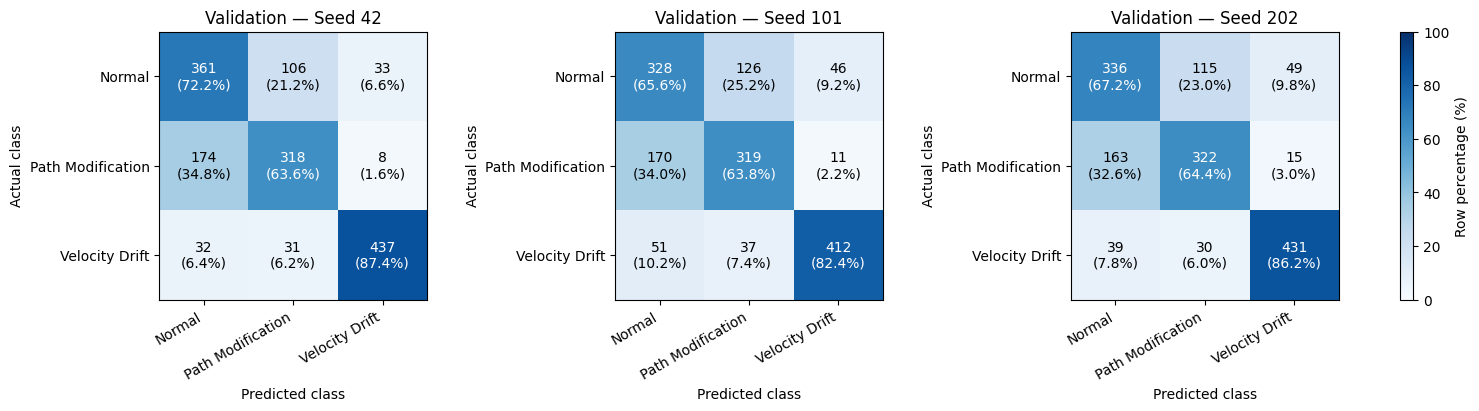

In [ ]:
# Step 13: Validation evaluation and confusion matrices
def evaluate_protonet(model, episodes):
    model.eval()
    accuracies, f1_scores, prediction_rows = [], [], []
    with torch.inference_mode():
        for episode_id, saved_episode in enumerate(episodes):
            episode = {
                k: v.to(DEVICE) if isinstance(v, torch.Tensor) else v
                for k, v in saved_episode.items()
            }
            _, accuracy, predictions, _ = protonet_forward(model, episode)
            actual = episode["query_y"].cpu().numpy()
            predicted = predictions.cpu().numpy()
            accuracies.append(accuracy.item())
            f1_scores.append(f1_score(actual, predicted, labels=CLASS_LABELS, average="macro", zero_division=0))
            for q_pos, (t, p) in enumerate(zip(actual, predicted)):
                prediction_rows.append({"Episode": episode_id, "Query position": q_pos, "Actual": int(t), "Predicted": int(p)})
    metrics = {
        "Accuracy (%)": np.mean(accuracies) * 100,
        "Episode accuracy SD (pp)": np.std(accuracies) * 100,
        "Mean episode macro-F1": np.mean(f1_scores)
    }
    return metrics, pd.DataFrame(prediction_rows)

validation_rows, validation_predictions, validation_confusions = [], {}, {}
class_rows, false_alarm_rows = [], []

for seed, model in resnet_models.items():
    metrics, preds = evaluate_protonet(model, shared_val_episodes_7)
    validation_rows.append({"Seed": seed, **metrics})
    validation_predictions[seed] = preds

    actual, predicted = preds["Actual"].to_numpy(), preds["Predicted"].to_numpy()
    cm = confusion_matrix(actual, predicted, labels=CLASS_LABELS)
    validation_confusions[seed] = cm
    prec, rec, f1, sup = precision_recall_fscore_support(actual, predicted, labels=CLASS_LABELS, zero_division=0)
    for i, name in enumerate(CLASS_NAMES):
        class_rows.append({
            "Seed": seed, "Class": name, "Precision (%)": prec[i]*100,
            "Recall (%)": rec[i]*100, "F1": f1[i], "Query appearances": int(sup[i])
        })
    false_alarm_rows.append({"Seed": seed, "Normal false-alarm rate (%)": (1 - rec[0]) * 100})

validation_results = pd.DataFrame(validation_rows)
display(validation_results.round(4))
display(pd.DataFrame(class_rows).round(4))
display(pd.DataFrame(false_alarm_rows).round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, (seed, cm) in zip(axes, validation_confusions.items()):
    pct = cm / cm.sum(axis=1, keepdims=True) * 100
    im = ax.imshow(pct, cmap="Blues", vmin=0, vmax=100)
    ax.set(xticks=range(3), yticks=range(3), xlabel="Predicted class", ylabel="Actual class", title=f"Validation — Seed {seed}")
    ax.set_xticklabels(CLASS_NAMES, rotation=30, ha="right")
    ax.set_yticklabels(CLASS_NAMES)
    for r in range(3):
        for c in range(3):
            ax.text(c, r, f"{cm[r, c]}\n({pct[r, c]:.1f}%)", ha="center", va="center", color="white" if pct[r, c] > 50 else "black")
fig.colorbar(im, ax=axes.tolist(), label="Row percentage (%)")
plt.show()

In [ ]:
# Step 14: 1-, 5-, and 10-shot comparisons (Original and Paired protocols)
SHOT_VALUES = [1, 5, 10]
few_shot_episodes_7 = {
    s: build_episodes(X_val_7, y_val_3, val_metadata_3, 100, n_shot=s, n_query=5, seed=2026 + s)[0]
    for s in SHOT_VALUES
}

# Build Paired episodes: identical query sets, nested support sets up to 10-shot
paired_episodes_7 = {1: [], 5: [], 10: []}
rng_paired = np.random.default_rng(2026)
for _ in range(100):
    sup_by_c, qry_by_c = {}, {}
    for c in CLASS_LABELS:
        c_idx = np.flatnonzero(y_val_3 == c)
        chosen = rng_paired.choice(c_idx, size=10 + 5, replace=False)
        sup_by_c[c] = chosen[:10]
        qry_by_c[c] = chosen[10:]
    qry_idx = np.concatenate([qry_by_c[c] for c in CLASS_LABELS])
    for s in SHOT_VALUES:
        sup_idx = np.concatenate([sup_by_c[c][:s] for c in CLASS_LABELS])
        paired_episodes_7[s].append({
            "support_x": torch.as_tensor(X_val_7[sup_idx], dtype=torch.float32),
            "support_y": torch.as_tensor(y_val_3[sup_idx], dtype=torch.long),
            "query_x": torch.as_tensor(X_val_7[qry_idx], dtype=torch.float32),
            "query_y": torch.as_tensor(y_val_3[qry_idx], dtype=torch.long),
        })

shot_rows = []
for protocol, ep_group in [("Original", few_shot_episodes_7), ("Paired", paired_episodes_7)]:
    for seed, model in resnet_models.items():
        for shot in SHOT_VALUES:
            m, _ = evaluate_protonet(model, ep_group[shot])
            shot_rows.append({"Protocol": protocol, "Seed": seed, "Shots": shot, **m})

shot_results = pd.DataFrame(shot_rows)
print("Accuracy (%)")
display(shot_results.pivot(index=["Protocol", "Seed"], columns="Shots", values="Accuracy (%)").round(2))
print("Mean episode macro-F1")
display(shot_results.pivot(index=["Protocol", "Seed"], columns="Shots", values="Mean episode macro-F1").round(4))

Accuracy (%)


Shots             1      5      10
Protocol Seed                     
Original 42    63.00  71.40  74.20
         101   61.33  71.33  69.67
         202   59.73  71.27  72.33
Paired   42    65.80  73.73  75.07
         101   62.47  70.27  71.67
         202   64.80  71.20  73.47

Mean episode macro-F1


Shots              1       5       10
Protocol Seed                        
Original 42    0.6080  0.7059  0.7355
         101   0.5942  0.7033  0.6916
         202   0.5759  0.7028  0.7183
Paired   42    0.6346  0.7294  0.7441
         101   0.6022  0.6933  0.7118
         202   0.6289  0.7044  0.7289

In [ ]:
# Step 15: Attack-strength breakdowns (Velocity Drift & Path Modification)
drift_positions = np.flatnonzero(y_val_3 == 2)
drift_row_map = np.full(len(y_val_3), -1, dtype=int)
drift_row_map[drift_positions] = np.arange(len(drift_positions))

drift_rows = []
for knots in DRIFT_CONDITIONS:
    cond_episodes = []
    for sup_idx, qry_idx in robust_plans:
        qx = X_val_7[qry_idx].copy()
        d_mask = y_val_3[qry_idx] == 2
        qx[d_mask] = drift_variants_7[knots][drift_row_map[qry_idx[d_mask]]]
        cond_episodes.append({
            "support_x": torch.as_tensor(X_val_7[sup_idx], dtype=torch.float32),
            "support_y": torch.as_tensor(y_val_3[sup_idx], dtype=torch.long),
            "query_x": torch.as_tensor(qx, dtype=torch.float32),
            "query_y": torch.as_tensor(y_val_3[qry_idx], dtype=torch.long),
        })
    for seed, model in resnet_models.items():
        m, preds = evaluate_protonet(model, cond_episodes)
        d_recall = (preds.loc[preds["Actual"] == 2, "Predicted"] == 2).mean() * 100
        drift_rows.append({"Seed": seed, "Drift (knots)": knots, **m, "Drift-type recall (%)": d_recall})

drift_results = pd.DataFrame(drift_rows)
for col in ["Drift-type recall (%)", "Accuracy (%)", "Mean episode macro-F1"]:
    print(col)
    display(drift_results.pivot(index="Seed", columns="Drift (knots)", values=col).reindex(columns=DRIFT_CONDITIONS).round(4))

# Path-modification recall by intensity
PATH_LEVELS = ["weak", "moderate", "strong"]
path_levels_arr = val_metadata_3["intensity"].fillna("").astype(str).str.lower().to_numpy()
query_rows_flat = np.concatenate([q for _, q in robust_plans])

path_rows = []
for seed, model in resnet_models.items():
    preds = validation_predictions[seed].copy()
    preds["Path intensity"] = path_levels_arr[query_rows_flat]
    for level in PATH_LEVELS:
        sel = preds[(preds["Actual"] == 1) & (preds["Path intensity"] == level)]
        path_rows.append({"Seed": seed, "Intensity": level, "Path-type recall (%)": (sel["Predicted"] == 1).mean() * 100})

print("Path-type recall (%)")
display(pd.DataFrame(path_rows).pivot(index="Seed", columns="Intensity", values="Path-type recall (%)").reindex(columns=PATH_LEVELS).round(2))

Drift-type recall (%)


Drift (knots),-20,-10,-5,5,10,20
Seed,,,,,,
42,100.0,96.4,66.4,67.6,96.8,100.0
101,100.0,98.0,64.0,66.0,96.0,100.0
202,100.0,94.6,70.8,65.2,94.8,100.0


Accuracy (%)


Drift (knots),-20,-10,-5,5,10,20
Seed,,,,,,
42,78.6000,77.4,67.4000,67.8000,77.5333,78.6000
101,76.4667,75.8,64.4667,65.1333,75.1333,76.4667
202,77.2000,75.4,67.4667,65.6000,75.4667,77.2000


Mean episode macro-F1


Drift (knots),-20,-10,-5,5,10,20
Seed,,,,,,
42,0.7752,0.7645,0.6698,0.6723,0.7657,0.7752
101,0.7527,0.7470,0.6401,0.6458,0.7408,0.7527
202,0.7597,0.7441,0.6692,0.6517,0.7439,0.7597


Path-type recall (%)


Intensity,weak,moderate,strong
Seed,,,
42,27.16,68.39,94.51
101,35.19,62.64,93.29
202,30.25,69.54,92.68


Step 16 Update ->
The original cell scores 100 aircraft, but 10 of them also supplied labeled examples to ProtoNet. We’ll exclude those 10 and score both versions of each of the remaining 90 aircraft.

In [ ]:
# Step 16: Paired Clean-vs-Attacked check & Aircraft-Group Bias diagnostic
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression

# NEW PART TO CHECK---> Evaluate clean/attacked pairs on aircraft outside the support set
support_ep0 = shared_val_episodes_7[0]
support_ids = set(map(str, support_ep0["support_aircraft"]))

# paired_idx gives the validation row for each clean/attacked pair.
pair_ids = val_metadata_3.iloc[paired_idx]["icao24"].astype(str).to_numpy()
keep = ~np.isin(pair_ids, list(support_ids))

kept_ids = pair_ids[keep]
attack_labels = y_val_3[paired_idx][keep]
clean = X_original_paired[keep]
attacked = X_attacked_paired[keep]
n_pairs = len(kept_ids)

assert n_pairs == len(set(kept_ids)) == 90
assert support_ids.isdisjoint(kept_ids)
assert (attack_labels == 1).sum() == (attack_labels == 2).sum() == 45
np.testing.assert_array_equal(attacked, X_val_7[paired_idx[keep]])

pair_episode = {
    "support_x": support_ep0["support_x"],
    "support_y": support_ep0["support_y"],
    "query_x": torch.as_tensor(
        np.concatenate([clean, attacked]), dtype=torch.float32
    ),
    "query_y": torch.as_tensor(
        np.concatenate([np.zeros(n_pairs, dtype=int), attack_labels]),
        dtype=torch.long,
    ),
}

paired_rows = []
for seed, model in sorted(resnet_models.items()):
    _, predictions = evaluate_protonet(model, [pair_episode])
    predicted = predictions["Predicted"].to_numpy()

    clean_ok = predicted[:n_pairs] == 0
    attack_ok = predicted[n_pairs:] == attack_labels

    paired_rows.append({
        "Seed": seed,
        "Paired aircraft": n_pairs,
        "Original recognized (%)": 100 * clean_ok.mean(),
        "Attack type recognized (%)": 100 * attack_ok.mean(),
        "Both correct (%)": 100 * (clean_ok & attack_ok).mean(),
    })

baseline_paired_results = pd.DataFrame(paired_rows)
display(baseline_paired_results.round(2))

# Aircraft-group initial observation diagnostic
X_initial = X_train_3_raw[:, 0, :]
diag_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
bias_scores = cross_val_score(diag_model, X_initial, y_train_3, cv=cv, scoring="accuracy")
print(f"Group-bias diagnostic accuracy: {bias_scores.mean()*100:.2f}% ± {bias_scores.std()*100:.2f} pp (Chance: 33.33%)")

,Seed,Paired aircraft,Original recognized (%),Attack type recognized (%),Both correct (%)
0,42,90,66.67,76.67,46.67
1,101,90,80.00,72.22,57.78
2,202,90,55.56,60.00,28.89


Group-bias diagnostic accuracy: 31.07% ± 1.27 pp (Chance: 33.33%)


In [ ]:
# Step 17: Construct 441-aircraft Test Set (1,323 windows) and run Final Evaluation
test_pool = window_index_df.loc[window_index_df["partition"] == "Test"].copy()
test_pool["local_start"] = test_pool["start_row"] - test_pool["flight_id"].map(flight_starts)
test_pool["flight_length"] = test_pool["flight_id"].map(flight_lengths)

eligible_test_pool = test_pool.loc[
    (test_pool["local_start"] >= HISTORY)
    & (test_pool["local_start"] + 50 <= test_pool["flight_length"])
].copy()

test_plan_base = (
    eligible_test_pool.groupby("icao24", group_keys=False)
    .sample(n=1, random_state=42)
    .sort_values("icao24")
    .reset_index(drop=True)
)

test_source = df_airspace.loc[
    df_airspace["flight_id"].isin(test_plan_base["flight_id"]), needed_columns
].copy()
test_flights = {
    fid: grp.sort_values("timestamp").reset_index(drop=True)
    for fid, grp in test_source.groupby("flight_id", sort=False)
}
del test_source

rng_test = np.random.default_rng(2026)
test_windows, test_records = [], []

for i, row in test_plan_base.iterrows():
    original = test_flights[row["flight_id"]]
    start = int(row["local_start"])
    intensity = ["weak", "moderate", "strong"][i % 3]
    knots = float(DRIFT_CONDITIONS[i % len(DRIFT_CONDITIONS)])

    # 1. Normal
    eng0 = engineer_complete_flight(original)
    test_windows.append(extract_four_features(eng0, start))
    test_records.append({"icao24": str(row["icao24"]), "label": 0, "intensity": "none", "drift_knots": 0.0})

    # 2. Path Modification
    mod1, _ = simulate_path_modification(original, start, intensity=intensity, seed=1000 + i)
    eng1 = engineer_complete_flight(mod1)
    test_windows.append(extract_four_features(eng1, start))
    test_records.append({"icao24": str(row["icao24"]), "label": 1, "intensity": intensity, "drift_knots": 0.0})

    # 3. Velocity Drift
    mod2, _ = simulate_velocity_drift(original, start, max_drift_knots=knots)
    eng2 = engineer_complete_flight(mod2)
    test_windows.append(extract_four_features(eng2, start))
    test_records.append({"icao24": str(row["icao24"]), "label": 2, "intensity": "none", "drift_knots": knots})

X_test_7_raw = build_7_features(np.stack(test_windows))
X_test_7 = scaler_7.transform(X_test_7_raw.reshape(-1, 7)).reshape(X_test_7_raw.shape).astype(np.float32)
test_metadata_3 = pd.DataFrame(test_records)
y_test_3 = test_metadata_3["label"].to_numpy(dtype=np.int64)

# Build 100 aircraft-disjoint test episodes
shared_test_episodes_7 = []
unique_test_aircraft = test_metadata_3["icao24"].unique()
for _ in range(100):
    chosen_ac = rng_test.choice(unique_test_aircraft, size=30, replace=False)
    sup_ac, qry_ac = chosen_ac[:15], chosen_ac[15:]
    sup_idx, qry_idx = [], []
    for c in CLASS_LABELS:
        c_sup_ac = sup_ac[c*5:(c+1)*5]
        c_qry_ac = qry_ac[c*5:(c+1)*5]
        sup_idx.extend(test_metadata_3.index[(test_metadata_3["icao24"].isin(c_sup_ac)) & (test_metadata_3["label"] == c)])
        qry_idx.extend(test_metadata_3.index[(test_metadata_3["icao24"].isin(c_qry_ac)) & (test_metadata_3["label"] == c)])
    shared_test_episodes_7.append({
        "support_x": torch.as_tensor(X_test_7[sup_idx], dtype=torch.float32),
        "support_y": torch.as_tensor(y_test_3[sup_idx], dtype=torch.long),
        "query_x": torch.as_tensor(X_test_7[qry_idx], dtype=torch.float32),
        "query_y": torch.as_tensor(y_test_3[qry_idx], dtype=torch.long),
    })

test_rows, test_confusions = [], {}
for seed, model in sorted(resnet_models.items()):
    m, preds = evaluate_protonet(model, shared_test_episodes_7)
    cm = confusion_matrix(preds["Actual"], preds["Predicted"], labels=CLASS_LABELS)
    rec = cm.diagonal() / cm.sum(axis=1) * 100
    test_rows.append({
        "Seed": seed, **m,
        "Normal recall (%)": rec[0], "Path recall (%)": rec[1],
        "Drift recall (%)": rec[2], "Normal false-alarm rate (%)": 100 - rec[0]
    })
    test_confusions[seed] = cm

test_results = pd.DataFrame(test_rows)
display(test_results.round(4))
display(test_results.drop(columns="Seed").agg(["mean", "std"]).T.round(4))

,Seed,Accuracy (%),Episode accuracy SD (pp),Mean episode macro-F1,Normal recall (%),Path recall (%),Drift recall (%),Normal false-alarm rate (%)
0,42,72.3333,11.2101,0.7156,69.8,62.8,84.4,30.2
1,101,71.5333,11.5799,0.7062,66.4,64.0,84.2,33.6
2,202,72.0000,10.8730,0.7102,68.6,58.8,88.6,31.4


,mean,std
Accuracy (%),71.9556,0.4018
Episode accuracy SD (pp),11.2210,0.3536
Mean episode macro-F1,0.7107,0.0048
Normal recall (%),68.2667,1.7243
Path recall (%),61.8667,2.7227
Drift recall (%),85.7333,2.4846
Normal false-alarm rate (%),31.7333,1.7243


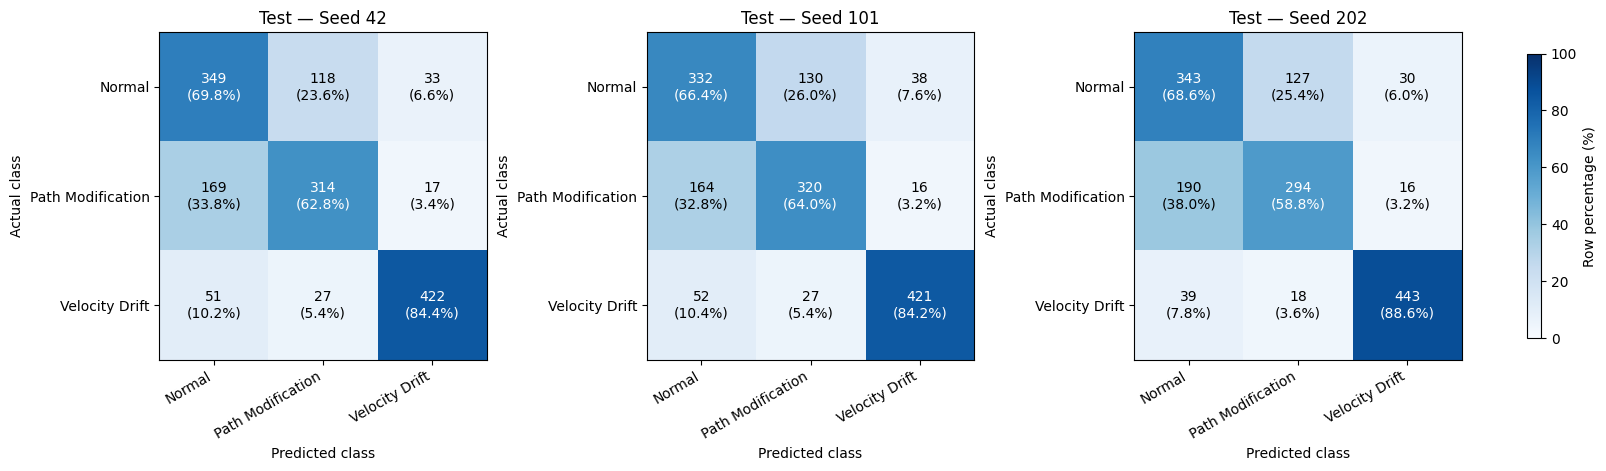

,Seed,Class,Precision (%),Recall (%),F1,Query appearances
0,42,Normal,61.3357,69.8,0.6529,500
1,42,Path Modification,68.4096,62.8,0.6548,500
2,42,Velocity Drift,89.4068,84.4,0.8683,500
3,101,Normal,60.5839,66.4,0.6336,500
4,101,Path Modification,67.0860,64.0,0.6551,500
5,101,Velocity Drift,88.6316,84.2,0.8636,500
6,202,Normal,59.9650,68.6,0.6399,500
7,202,Path Modification,66.9704,58.8,0.6262,500
8,202,Velocity Drift,90.5930,88.6,0.8959,500


In [ ]:
# Step 18: Test confusion matrices and per-class precision, recall, and F1
test_predictions = {}
test_class_rows = []

for seed, model in sorted(resnet_models.items()):
    _, preds = evaluate_protonet(model, shared_test_episodes_7)
    test_predictions[seed] = preds

    prec, rec, f1, sup = precision_recall_fscore_support(
        preds["Actual"], preds["Predicted"], labels=CLASS_LABELS, zero_division=0
    )
    for i, class_name in enumerate(CLASS_NAMES):
        test_class_rows.append({
            "Seed": seed,
            "Class": class_name,
            "Precision (%)": prec[i] * 100,
            "Recall (%)": rec[i] * 100,
            "F1": f1[i],
            "Query appearances": int(sup[i])
        })

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
for ax, seed in zip(axes, sorted(test_confusions)):
    cm = test_confusions[seed]
    row_pct = cm / cm.sum(axis=1, keepdims=True) * 100
    im = ax.imshow(row_pct, cmap="Blues", vmin=0, vmax=100)
    for i in range(3):
        for j in range(3):
            ax.text(
                j, i, f"{cm[i, j]}\n({row_pct[i, j]:.1f}%)",
                ha="center", va="center",
                color="white" if row_pct[i, j] > 50 else "black"
            )
    ax.set(
        title=f"Test — Seed {seed}",
        xlabel="Predicted class",
        ylabel="Actual class",
        xticks=range(3),
        yticks=range(3)
    )
    ax.set_xticklabels(CLASS_NAMES, rotation=30, ha="right")
    ax.set_yticklabels(CLASS_NAMES)

fig.colorbar(im, ax=axes.tolist(), label="Row percentage (%)", shrink=0.85)
plt.show()

test_class_results = pd.DataFrame(test_class_rows)
display(test_class_results.round(4))

,Seed,Accuracy (%)_validation,Mean episode macro-F1_validation,Accuracy (%)_test,Mean episode macro-F1_test,Accuracy change (pp),Macro-F1 change
0,42,74.4,0.7370,72.3333,0.7156,-2.0667,-0.0214
1,101,70.6,0.6996,71.5333,0.7062,0.9333,0.0066
2,202,72.6,0.7185,72.0000,0.7102,-0.6000,-0.0084


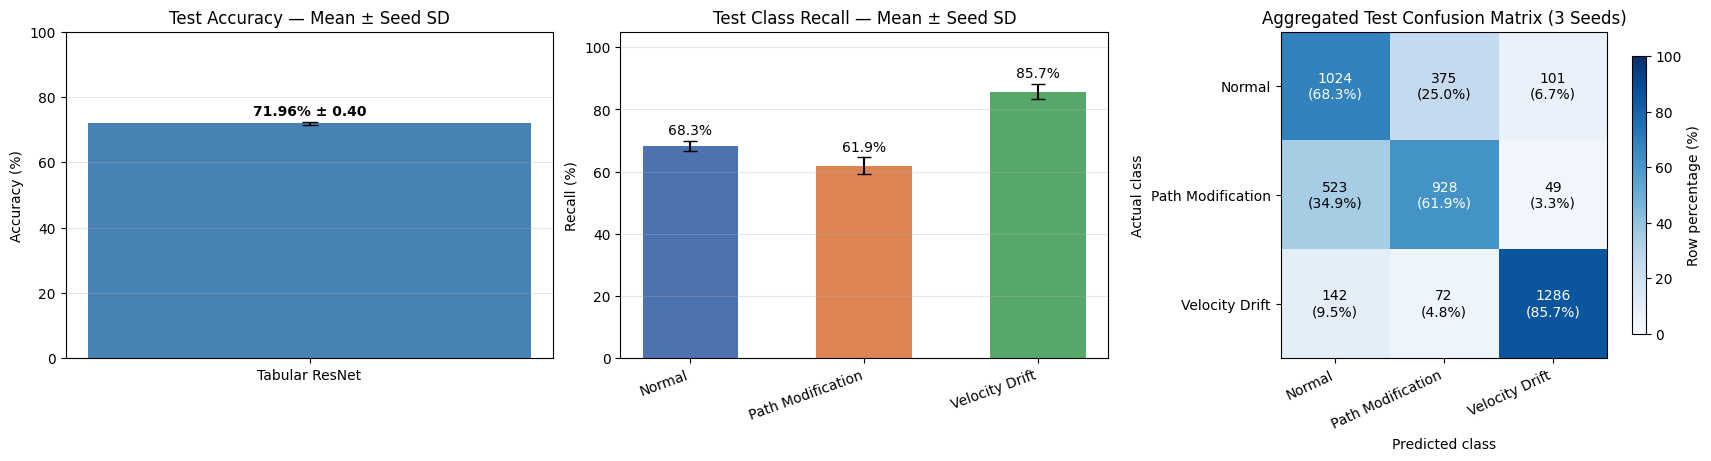

In [ ]:
# Step 19: Validation vs. Test comparison and Final Summary Figures
comparison_metrics = ["Accuracy (%)", "Mean episode macro-F1"]

validation_test_by_seed = (
    validation_results[["Seed"] + comparison_metrics]
    .merge(
        test_results[["Seed"] + comparison_metrics],
        on="Seed",
        suffixes=("_validation", "_test")
    )
)
validation_test_by_seed["Accuracy change (pp)"] = (
    validation_test_by_seed["Accuracy (%)_test"]
    - validation_test_by_seed["Accuracy (%)_validation"]
)
validation_test_by_seed["Macro-F1 change"] = (
    validation_test_by_seed["Mean episode macro-F1_test"]
    - validation_test_by_seed["Mean episode macro-F1_validation"]
)
display(validation_test_by_seed.round(4))

# 3-Panel Final Test Summary Figure
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), constrained_layout=True)

# 1. Test Accuracy (Mean ± Seed SD)
acc_mean = test_results["Accuracy (%)"].mean()
acc_sd = test_results["Accuracy (%)"].std(ddof=1)
axes[0].bar(["Tabular ResNet"], [acc_mean], yerr=[acc_sd], capsize=6, color="steelblue", width=0.4)
axes[0].set(ylim=(0, 100), ylabel="Accuracy (%)", title="Test Accuracy — Mean ± Seed SD")
axes[0].text(0, acc_mean + acc_sd + 2, f"{acc_mean:.2f}% ± {acc_sd:.2f}", ha="center", fontweight="bold")
axes[0].grid(axis="y", alpha=0.3)

# 2. Class-wise Test Recall (Mean ± Seed SD)
recall_cols = ["Normal recall (%)", "Path recall (%)", "Drift recall (%)"]
rec_means = [test_results[c].mean() for c in recall_cols]
rec_sds = [test_results[c].std(ddof=1) for c in recall_cols]
x_pos = np.arange(len(CLASS_NAMES))
axes[1].bar(x_pos, rec_means, yerr=rec_sds, capsize=5, color=["#4c72b0", "#dd8452", "#55a868"], width=0.55)
axes[1].set(xticks=x_pos, ylim=(0, 105), ylabel="Recall (%)", title="Test Class Recall — Mean ± Seed SD")
axes[1].set_xticklabels(CLASS_NAMES, rotation=20, ha="right")
for i, (m, s) in enumerate(zip(rec_means, rec_sds)):
    axes[1].text(i, m + s + 2, f"{m:.1f}%", ha="center")
axes[1].grid(axis="y", alpha=0.3)

# 3. Aggregated Confusion Matrix Across All 3 Seeds
cm_total = sum(test_confusions.values())
cm_pct = cm_total / cm_total.sum(axis=1, keepdims=True) * 100
im = axes[2].imshow(cm_pct, cmap="Blues", vmin=0, vmax=100)
axes[2].set(
    xticks=range(3), yticks=range(3),
    xlabel="Predicted class", ylabel="Actual class",
    title="Aggregated Test Confusion Matrix (3 Seeds)"
)
axes[2].set_xticklabels(CLASS_NAMES, rotation=25, ha="right")
axes[2].set_yticklabels(CLASS_NAMES)
for i in range(3):
    for j in range(3):
        axes[2].text(
            j, i, f"{cm_total[i, j]}\n({cm_pct[i, j]:.1f}%)",
            ha="center", va="center",
            color="white" if cm_pct[i, j] > 50 else "black"
        )
fig.colorbar(im, ax=axes[2], label="Row percentage (%)", shrink=0.85)
plt.savefig(RUN_DIR / "final_test_summary_figures.png", dpi=300)
plt.show()

In [ ]:
# # this code saves all evaluation tables to RUN_DIR
# # could we use the onnx to save the weightss

# validation_results.to_csv(RUN_DIR / "validation_results.csv", index=False)
# shot_results.to_csv(RUN_DIR / "shot_comparison_results.csv", index=False)
# drift_results.to_csv(RUN_DIR / "drift_strength_results.csv", index=False)
# test_results.to_csv(RUN_DIR / "test_results_by_seed.csv", index=False)
# test_class_results.to_csv(RUN_DIR / "test_class_metrics.csv", index=False)
# validation_test_by_seed.to_csv(RUN_DIR / "validation_vs_test_comparison.csv", index=False)

# print("All evaluation tables and figures saved to:", RUN_DIR)

Prepare the clean and weak-attack pairs

In [ ]:
# Step 20A — Build matched clean and weak validation windows (7 features)

val_pairs_20 = val_metadata_3.loc[
    val_metadata_3["label"].eq(1)
    & val_metadata_3["icao24"].astype(str).isin(kept_ids)
].copy()
assert len(val_pairs_20) == val_pairs_20["icao24"].nunique() == 45

# Reuse the clean windows from Step 16, matched by validation row.
clean_positions = pd.Index(paired_idx).get_indexer(val_pairs_20.index)
assert (clean_positions >= 0).all()
clean_20 = X_original_paired[clean_positions]

# Recreate each path attack at weak strength using its original direction.
source_20 = df_airspace.loc[
    df_airspace["flight_id"].isin(val_pairs_20["flight_id"]), needed_columns
]
flights_20 = {
    fid: group.sort_values("timestamp").reset_index(drop=True)
    for fid, group in source_20.groupby("flight_id", sort=False)
}

weak_windows = []
for row in val_pairs_20.itertuples():
    start = int(row.local_start)
    weak_flight, _ = simulate_path_modification(
        flights_20[row.flight_id], start, intensity="weak",
        attack_length=30, recovery_length=20, seed=int(row.attack_seed),
    )
    engineered = engineer_complete_flight(weak_flight)
    weak_windows.append(extract_four_features(engineered, start))

raw_20 = build_7_features(np.stack(weak_windows))
weak_20 = scaler_7.transform(raw_20.reshape(-1, 7)).reshape(raw_20.shape)
weak_20 = weak_20.astype(np.float32)

# Originally weak attacks should reproduce their saved validation inputs.
was_weak = val_pairs_20["intensity"].eq("weak").to_numpy()
assert was_weak.any()
np.testing.assert_allclose(
    weak_20[was_weak], X_val_7[val_pairs_20.index[was_weak]],
    rtol=1e-5, atol=1e-5,
)

assert clean_20.shape == weak_20.shape == (45, 30, 7)
assert np.isfinite(clean_20).all() and np.isfinite(weak_20).all()

display(pd.DataFrame({
    "Version": ["Clean", "Weak path (100 m)"],
    "Aircraft": [len(clean_20), len(weak_20)],
    "Window shape": [clean_20.shape[1:], weak_20.shape[1:]],
}))

,Version,Aircraft,Window shape
0,Clean,45,"(30, 7)"
1,Weak path (100 m),45,"(30, 7)"


Score  existing Tabular ResNet + ProtoNet on those pairs. This gives the baseline to compare against.

In [ ]:
# Step 20B — Seven-feature baseline on matched validation windows

val_ids_20 = val_metadata_3["icao24"].astype(str).to_numpy()
pair_ids_20 = val_pairs_20["icao24"].astype(str).to_numpy()

# Keep these plans so the four new methods see exactly the same examples.
plans_20 = []
baseline_rows_20 = []

assert len(robust_plans) == 100
assert set(resnet_models) == {42, 101, 202}

for episode_id, (support_idx, _) in enumerate(robust_plans):
    query_idx = np.flatnonzero(~np.isin(pair_ids_20, val_ids_20[support_idx]))
    plans_20.append((support_idx, query_idx))

    n = len(query_idx)
    assert n > 0
    queries = np.concatenate([clean_20[query_idx], weak_20[query_idx]])
    episode = {
        "support_x": torch.as_tensor(X_val_7[support_idx], dtype=torch.float32),
        "support_y": torch.as_tensor(y_val_3[support_idx], dtype=torch.long),
        "query_x": torch.as_tensor(queries, dtype=torch.float32),
        "query_y": torch.tensor([0] * n + [1] * n, dtype=torch.long),
    }

    for seed, model in sorted(resnet_models.items()):
        _, predictions = evaluate_protonet(model, [episode])
        pred = predictions["Predicted"].to_numpy()

        # First half is clean (class 0). Second half is weak path (class 1).
        baseline_rows_20.append({
            "Seed": seed,
            "Episode": episode_id,
            "Weak path recall (%)": 100 * (pred[n:] == 1).mean(),
            "Clean false alarms (%)": 100 * (pred[:n] != 0).mean(),
        })

baseline_scores_20 = pd.DataFrame(baseline_rows_20)
metrics_20 = ["Weak path recall (%)", "Clean false alarms (%)"]
baseline_summary_20 = baseline_scores_20.groupby("Seed")[metrics_20].mean()
baseline_summary_20.loc["Mean across seeds"] = baseline_summary_20.mean()

display(baseline_summary_20.round(2))

,Weak path recall (%),Clean false alarms (%)
Seed,,
42,31.83,27.46
101,29.97,24.33
202,31.65,29.52
Mean across seeds,31.15,27.11


# random convolutional kernels + linear head
Finding -> tried random convolutional kernels + a linear head using your seven features. On validation, it recognized slightly more weak attacks than Tabular ResNet + ProtoNet (33.70% vs. 31.15%), but it also flagged many more clean windows as attacks (46.85% vs. 27.11%).

So lastly the weak-attack recognition improved slightly, but false alarms increased sharply. The method didn’t meet my goal of improving both.

In [ ]:
# Step 21A — Extract patterns from seven-feature windows using fixed random filters
import torch.nn.functional as F

def make_kernel_bank(seed):
    rng = torch.Generator().manual_seed(seed)
    bank = []

    # 64 filters at each of three lengths = 192 filters per seed.
    for length in (3, 7, 11):
        weights = torch.randn(64, 7, length, generator=rng)
        weights -= weights.mean(dim=(1, 2), keepdim=True)
        weights /= (7 * length) ** 0.5
        bias = torch.rand(64, generator=rng) * 2 - 1
        bank.append((weights, bias))

    return bank


@torch.inference_mode()
def kernel_features(windows, bank):
    # Conv1d expects (windows, features, time).
    x = torch.as_tensor(windows, dtype=torch.float32).transpose(1, 2)
    summaries = []
    for weights, bias in bank:
        response = F.conv1d(x, weights, bias)
        summaries.append(response.amax(dim=2))
        summaries.append((response > 0).float().mean(dim=2))
    return torch.cat(summaries, dim=1).numpy()


kernel_banks_21 = {}
features_21 = {}
for seed in (42, 101, 202):
    bank = make_kernel_bank(seed)
    kernel_banks_21[seed] = bank
    features_21[seed] = {
        "Validation": kernel_features(X_val_7, bank),
        "Clean": kernel_features(clean_20, bank),
        "Weak": kernel_features(weak_20, bank),
    }
    for values in features_21[seed].values():
        assert values.shape[1] == 384 and np.isfinite(values).all()

display(pd.DataFrame([
    {"Dataset": name, "Windows": len(values), "Filter outputs per window": values.shape[1]}
    for name, values in features_21[42].items()
]))

,Dataset,Windows,Filter outputs per window
0,Validation,150,384
1,Clean,45,384
2,Weak,45,384


In [ ]:
# Step 21B — Evaluate random convolutional kernels + a five-shot linear head

from sklearn.linear_model import RidgeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

kernel_rows_21 = []

for seed, features in features_21.items():
    for episode_id, (support_idx, query_idx) in enumerate(plans_20):
        # 1. Get the 15 labeled examples for this round.
        support_x = features["Validation"][support_idx]
        support_y = y_val_3[support_idx]
        assert np.array_equal(np.bincount(support_y, minlength=3), [5, 5, 5])

        # 2. Scale the filter outputs and fit a fresh linear classifier.
        # Both steps learn only from this round's labeled examples.
        head = make_pipeline(StandardScaler(), RidgeClassifier(alpha=1.0))
        head.fit(support_x, support_y)

        # 3. Predict on the clean and weak versions of the same aircraft.
        clean_pred = head.predict(features["Clean"][query_idx])
        weak_pred = head.predict(features["Weak"][query_idx])

        kernel_rows_21.append({
            "Seed": seed,
            "Episode": episode_id,
            "Weak path recall (%)": 100 * (weak_pred == 1).mean(),
            "Clean false alarms (%)": 100 * (clean_pred != 0).mean(),
        })

# 4. Average the 100 rounds per seed, just as we did for the baseline.
kernel_scores_21 = pd.DataFrame(kernel_rows_21)
assert len(kernel_scores_21) == 300  # 3 filter seeds × 100 rounds

kernel_summary_21 = kernel_scores_21.groupby("Seed")[metrics_20].mean()
kernel_summary_21.loc["Mean across seeds"] = kernel_summary_21.mean()
display(kernel_summary_21.round(2))

,Weak path recall (%),Clean false alarms (%)
Seed,,
42,33.06,45.71
101,33.15,46.51
202,34.89,48.32
Mean across seeds,33.70,46.85


# MAML / Gradient based meta learning
The questiion now is :does MAML recognize more weak path attacks and raise fewer false alarms than your baseline


**Output** -> Using the same seven features and validation episodes, MAML detected weak path attacks more often than ProtoNet across all three seeds. The average false-alarm rate increased, so the result shows a trade-off.
**MAML was better at recognizing weak path attacks on validation, but it also raised more false alarms on average.**

In [ ]:
# Step 22A — Check one MAML training episode using the original seven features
from torch.func import functional_call

def make_maml_model():
    return nn.Sequential(
        TabularResNetEncoder(num_features=7, embedding_dim=32),
        nn.Linear(32, 3),  # Normal, Path Modification, Velocity Drift
    ).to(DEVICE)


def adapt_maml(model, support_x, support_y, step_size=0.01, meta_train=True):
    # Take one temporary learning step using only the support examples.
    params = dict(model.named_parameters())
    support_logits = model(support_x)
    support_loss = F.cross_entropy(support_logits, support_y)
    grads = torch.autograd.grad(
        support_loss, params.values(), create_graph=meta_train
    )
    return {
        name: weight - step_size * grad
        for (name, weight), grad in zip(params.items(), grads)
    }


torch.manual_seed(42)
check_model = make_maml_model()
ep = shared_train_episodes_3[0]

support_x = ep["support_x"].to(DEVICE)
support_y = ep["support_y"].to(DEVICE)
query_x = ep["query_x"].to(DEVICE)
query_y = ep["query_y"].to(DEVICE)

assert set(ep["support_aircraft"]).isdisjoint(ep["query_aircraft"])

adapted = adapt_maml(check_model, support_x, support_y)
query_logits = functional_call(check_model, adapted, (query_x,))
query_loss = F.cross_entropy(query_logits, query_y)

# Check that the query loss reaches the original starting weights.
meta_grads = torch.autograd.grad(query_loss, check_model.parameters())
gradient_ok = (
    all(torch.isfinite(g).all().item() for g in meta_grads)
    and any(g.abs().max().item() > 0 for g in meta_grads)
)
assert query_logits.shape == (15, 3) and gradient_ok

display(pd.DataFrame([{
    "Support windows": len(support_y),
    "Query windows": len(query_y),
    "Input features": support_x.shape[-1],
    "MAML gradient check": gradient_ok,
}]))

,Support windows,Query windows,Input features,MAML gradient check
0,15,15,7,True


In [ ]:
# Step 22B — Train one seven-feature MAML model per seed

assert len(shared_train_episodes_3) == 300

maml_models_22 = {}
maml_training_rows_22 = []

for seed in (42, 101, 202):
    torch.manual_seed(seed)
    model = make_maml_model()
    model.train()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    query_accuracies = []

    for ep in shared_train_episodes_3:
        support_x = ep["support_x"].to(DEVICE)
        support_y = ep["support_y"].to(DEVICE)
        query_x = ep["query_x"].to(DEVICE)
        query_y = ep["query_y"].to(DEVICE)

        # Practice: take one temporary step using the support examples.
        optimizer.zero_grad()
        adapted = adapt_maml(model, support_x, support_y,
                             step_size=0.01, meta_train=True)

        # Quiz: use the temporary weights to predict the query labels.
        logits = functional_call(model, adapted, (query_x,))
        loss = F.cross_entropy(logits, query_y)
        assert torch.isfinite(loss), f"Non-finite training loss for seed {seed}"

        # Use the quiz mistakes to improve the model's starting weights.
        loss.backward()
        optimizer.step()

        accuracy = (logits.detach().argmax(dim=1) == query_y).float().mean()
        query_accuracies.append(accuracy.item())

    maml_models_22[seed] = model.eval()
    torch.save(model.state_dict(), RUN_DIR / f"maml_7f_seed_{seed}.pth")

    maml_training_rows_22.append({
        "Seed": seed,
        "Training updates": len(query_accuracies),
        "Mean training query accuracy, last 50 updates (%)":
            100 * np.mean(query_accuracies[-50:]),
    })

display(pd.DataFrame(maml_training_rows_22).round(2))

,Seed,Training updates,"Mean training query accuracy, last 50 updates (%)"
0,42,300,88.40
1,101,300,87.47
2,202,300,88.40


In [ ]:
# Step 22C — Evaluate seven-feature MAML on matched validation windows

assert len(plans_20) == 100
assert set(maml_models_22) == {42, 101, 202}

maml_rows_22 = []

for episode_id, (support_idx, query_idx) in enumerate(plans_20):
    support_x = torch.as_tensor(
        X_val_7[support_idx], dtype=torch.float32, device=DEVICE
    )
    support_y = torch.as_tensor(
        y_val_3[support_idx], dtype=torch.long, device=DEVICE
    )

    # Clean windows first, then weak attacks in the same aircraft order.
    n = len(query_idx)
    queries = np.concatenate([clean_20[query_idx], weak_20[query_idx]])
    query_x = torch.as_tensor(queries, dtype=torch.float32, device=DEVICE)

    for seed, model in sorted(maml_models_22.items()):
        model.eval()

        # Use support labels for one temporary update, as in training.
        with torch.enable_grad():
            adapted = adapt_maml(
                model, support_x, support_y, step_size=0.01, meta_train=False
            )

        # Score the query windows without updating the trained model.
        with torch.no_grad():
            logits = functional_call(model, adapted, (query_x,))
            pred = logits.argmax(dim=1).cpu().numpy()

        maml_rows_22.append({
            "Seed": seed,
            "Episode": episode_id,
            "Weak path recall (%)": 100 * (pred[n:] == 1).mean(),
            "Clean false alarms (%)": 100 * (pred[:n] != 0).mean(),
        })

maml_scores_22 = pd.DataFrame(maml_rows_22)
assert len(maml_scores_22) == 300

maml_summary_22 = maml_scores_22.groupby("Seed")[metrics_20].mean()
maml_summary_22.loc["Mean across seeds"] = maml_summary_22.mean()
display(maml_summary_22.round(2))

,Weak path recall (%),Clean false alarms (%)
Seed,,
42,43.43,23.03
101,46.27,39.05
202,46.50,27.49
Mean across seeds,45.40,29.86


# Replaced Euclidean distance to prototypes with Relation Network

Output ->
Replacing Euclidean distance with a learned relation score increased weak-path recall by 4.02 percentage points, but clean false alarms increased by 11.58 points. MAML caught more weak attacks and raised fewer false alarms than the Relation Network on this validation set


| Seven-feature method | Weak path recall ↑ | Clean false alarms ↓ |
|---|---:|---:|
| Tabular ResNet + ProtoNet | 31.15% | 27.11% |
| Tabular ResNet + Relation Network | 35.17% | 38.69% |
| MAML | 45.40% | 29.86% |

In [ ]:
# Step 23A — Build the seven-feature Relation Network and check one episode

class RelationNet7(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = TabularResNetEncoder(num_features=7, embedding_dim=32)

        # Each pair contains 32 numbers for the window and 32 for the class reference.
        self.relation_head = nn.Sequential(
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, support_x, support_y, query_x):
        support = self.encoder(support_x)
        queries = self.encoder(query_x)
        classes = torch.unique(support_y, sorted=True)

        # Average the labeled examples to make one reference per class.
        prototypes = torch.stack([
            support[support_y == label].mean(dim=0) for label in classes
        ])

        # Pair every query with every class reference and score each pair.
        query_grid = queries[:, None, :].expand(-1, len(classes), -1)
        prototype_grid = prototypes[None, :, :].expand(len(queries), -1, -1)
        pairs = torch.cat([query_grid, prototype_grid], dim=-1)
        scores = self.relation_head(pairs).squeeze(-1)
        return scores, classes


# Reuse one of the same training episodes as the baseline.
episode = shared_train_episodes_3[0]
check_model = RelationNet7().to(DEVICE)
scores, classes = check_model(
    episode["support_x"].to(DEVICE),
    episode["support_y"].to(DEVICE),
    episode["query_x"].to(DEVICE)
)

# Check that the correct class can provide a learning signal.
targets = torch.searchsorted(classes, episode["query_y"].to(DEVICE))
loss = F.cross_entropy(scores, targets)
loss.backward()

def has_learning_signal(module):
    grads = [p.grad for p in module.parameters() if p.requires_grad]
    return (
        all(g is not None and torch.isfinite(g).all().item() for g in grads)
        and any(g.abs().max().item() > 0 for g in grads)
    )

display(pd.DataFrame([{
    "Input features": episode["query_x"].shape[-1],
    "Score shape": tuple(scores.shape),
    "Finite loss": torch.isfinite(loss).item(),
    "Encoder gradient OK": has_learning_signal(check_model.encoder),
    "Relation head gradient OK": has_learning_signal(check_model.relation_head)
}]))

,Input features,Score shape,Finite loss,Encoder gradient OK,Relation head gradient OK
0,7,"(15, 3)",True,True,True


In [ ]:
# Step 23B — Train and save one seven-feature Relation Network per seed

relation_models_23 = {}
training_rows_23 = []

for seed in TRAINING_CONFIG["model_seeds"]:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # Start each run with fresh weights.
    model = RelationNet7().to(DEVICE)
    model.train()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    query_accuracies = []

    for update, episode in enumerate(shared_train_episodes_3, start=1):
        support_x = episode["support_x"].to(DEVICE)
        support_y = episode["support_y"].to(DEVICE)
        query_x = episode["query_x"].to(DEVICE)
        query_y = episode["query_y"].to(DEVICE)

        # Score each query against the three class references.
        optimizer.zero_grad()
        scores, classes = model(support_x, support_y, query_x)
        targets = torch.searchsorted(classes, query_y)
        loss = F.cross_entropy(scores, targets)

        if not torch.isfinite(loss).item():
            raise ValueError(f"Non-finite loss at seed {seed}, update {update}")

        # Use the query mistakes to update the encoder and relation head.
        loss.backward()
        optimizer.step()

        with torch.no_grad():
            predictions = classes[scores.argmax(dim=1)]
            accuracy = (predictions == query_y).float().mean().item()
            query_accuracies.append(accuracy)

    model.eval()
    relation_models_23[seed] = model
    torch.save(model.state_dict(), RUN_DIR / f"relation_net_7f_seed_{seed}.pth")

    training_rows_23.append({
        "Seed": seed,
        "Training updates": len(query_accuracies),
        "Mean training query accuracy, last 50 updates (%)":
            round(100 * np.mean(query_accuracies[-50:]), 2)
    })

display(pd.DataFrame(training_rows_23))

,Seed,Training updates,"Mean training query accuracy, last 50 updates (%)"
0,42,300,81.07
1,101,300,66.40
2,202,300,66.93


In [ ]:
# Step 23C — Evaluate the Relation Network on the shared validation episodes

val_x_23 = torch.as_tensor(X_val_7, dtype=torch.float32, device=DEVICE)
val_y_23 = torch.as_tensor(y_val_3, dtype=torch.long, device=DEVICE)
clean_x_23 = torch.as_tensor(clean_20, dtype=torch.float32, device=DEVICE)
weak_x_23 = torch.as_tensor(weak_20, dtype=torch.float32, device=DEVICE)

normal_label = 0
path_label = 1
rows_23 = []

with torch.no_grad():
    for seed, model in relation_models_23.items():
        model.eval()

        for episode_id, (support_idx, query_idx) in enumerate(plans_20):
            support_idx = torch.as_tensor(support_idx, dtype=torch.long, device=DEVICE)
            query_idx = torch.as_tensor(query_idx, dtype=torch.long, device=DEVICE)

            # Use the same reference examples for both versions of each window.
            support_x = val_x_23[support_idx]
            support_y = val_y_23[support_idx]
            queries = torch.cat([clean_x_23[query_idx], weak_x_23[query_idx]])

            scores, classes = model(support_x, support_y, queries)
            predictions = classes[scores.argmax(dim=1)]
            clean_pred, weak_pred = predictions.chunk(2)

            rows_23.append({
                "Seed": seed,
                "Episode": episode_id,
                "Weak path recall (%)":
                    100 * (weak_pred == path_label).float().mean().item(),
                "Clean false alarms (%)":
                    100 * (clean_pred != normal_label).float().mean().item()
            })

# Average episodes within each seed, then give each seed equal weight.
relation_scores_23 = pd.DataFrame(rows_23)
metrics_23 = ["Weak path recall (%)", "Clean false alarms (%)"]
relation_summary_23 = relation_scores_23.groupby("Seed")[metrics_23].mean()
relation_summary_23.loc["Mean across seeds"] = relation_summary_23.mean()
display(relation_summary_23.round(2))

,Weak path recall (%),Clean false alarms (%)
Seed,,
42,27.78,24.07
101,44.62,48.52
202,33.10,43.48
Mean across seeds,35.17,38.69


# TCN (dilated causal convolutions)
The question is whether reading the 30 flight measurements as a sequence helps detect a subtle path change. Changed the encoder and use the original ProtoNet distance rule so I can compare the TCN directly with the Tabular ResNet baseline.

In [ ]:
# Step 24A — Build a seven-feature TCN and check one training episode

class TCNEncoder7(nn.Module):
    def __init__(self):
        super().__init__()
        self.input_projection = nn.Conv1d(7, 32, kernel_size=1)
        self.layers = nn.ModuleList([
            nn.Conv1d(32, 32, kernel_size=3, dilation=d)
            for d in (1, 2, 4, 8)
        ])

    def encode_steps(self, windows):
        # Colab data is [windows, time, features]. Conv1d needs features first.
        x = self.input_projection(windows.transpose(1, 2))

        for layer in self.layers:
            # Pad only on the left so each row can use only present and past rows.
            left_pad = (layer.kernel_size[0] - 1) * layer.dilation[0]
            history = F.pad(x, (left_pad, 0))
            x = F.relu(x + layer(history))
        return x

    def forward(self, windows):
        # The final time step can see all 30 rows and gives ProtoNet 32 numbers.
        return self.encode_steps(windows)[:, :, -1]


# Use one existing training episode for the check.
episode_24 = {
    key: shared_train_episodes_3[0][key].to(DEVICE)
    for key in ("support_x", "support_y", "query_x", "query_y")
}
check_tcn = TCNEncoder7().to(DEVICE)
loss_24, _, _, _ = protonet_forward(check_tcn, episode_24)
loss_24.backward()

queries = episode_24["query_x"]
with torch.no_grad():
    midpoint = queries.shape[1] // 2
    changed = queries.clone()
    changed[:, midpoint:, :] += 10
    original_steps = check_tcn.encode_steps(queries)
    changed_steps = check_tcn.encode_steps(changed)
    causal_ok = torch.allclose(
        original_steps[:, :, :midpoint], changed_steps[:, :, :midpoint]
    )

display(pd.DataFrame([{
    "Input window": tuple(queries.shape[1:]),
    "Query embeddings": tuple(check_tcn(queries).shape),
    "Causal check": causal_ok,
    "Finite loss": torch.isfinite(loss_24).item(),
    "Gradient check": has_learning_signal(check_tcn)
}]))

,Input window,Query embeddings,Causal check,Finite loss,Gradient check
0,"(30, 7)","(15, 32)",True,True,True


In [ ]:
# Step 24B — Train and save a seven-feature TCN + ProtoNet for each seed

tcn_models_24 = {}
training_rows_24 = []

for seed in TRAINING_CONFIG["model_seeds"]:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # Start a fresh TCN for this seed.
    encoder = TCNEncoder7().to(DEVICE)
    encoder.train()
    optimizer = torch.optim.Adam(encoder.parameters(), lr=0.001)
    query_accuracies = []

    for update, episode in enumerate(shared_train_episodes_3, start=1):
        episode_on_device = {
            key: episode[key].to(DEVICE)
            for key in ("support_x", "support_y", "query_x", "query_y")
        }

        # Use the same ProtoNet decision rule as the baseline.
        optimizer.zero_grad()
        loss, accuracy, _, _ = protonet_forward(encoder, episode_on_device)

        if not torch.isfinite(loss).item():
            raise ValueError(f"Non-finite loss at seed {seed}, update {update}")

        loss.backward()
        optimizer.step()
        query_accuracies.append(accuracy.item())

    # Keep the trained encoder for validation and save its weights.
    encoder.eval()
    tcn_models_24[seed] = encoder
    torch.save(encoder.state_dict(), RUN_DIR / f"tcn_protonet_7f_seed_{seed}.pth")

    training_rows_24.append({
        "Seed": seed,
        "Training updates": len(query_accuracies),
        "Mean training query accuracy, last 50 updates (%)":
            round(100 * np.mean(query_accuracies[-50:]), 2)
    })

display(pd.DataFrame(training_rows_24))

,Seed,Training updates,"Mean training query accuracy, last 50 updates (%)"
0,42,300,73.07
1,101,300,72.67
2,202,300,71.20


In [ ]:
# Step 24C — Measure weak-path recall and clean false alarms for TCN + ProtoNet

rows_24 = []

with torch.no_grad():
    for seed, encoder in tcn_models_24.items():
        encoder.eval()

        # Encode each window once. Reuse these results across validation episodes.
        val_embeddings = encoder(val_x_23)
        clean_embeddings = encoder(clean_x_23)
        weak_embeddings = encoder(weak_x_23)

        for episode_id, (support_idx, query_idx) in enumerate(plans_20):
            support_idx = torch.as_tensor(support_idx, dtype=torch.long, device=DEVICE)
            query_idx = torch.as_tensor(query_idx, dtype=torch.long, device=DEVICE)

            # Build one prototype per class from this episode's labeled examples.
            support = val_embeddings[support_idx]
            labels = val_y_23[support_idx]
            classes = torch.unique(labels, sorted=True)
            prototypes = torch.stack([
                support[labels == label].mean(dim=0) for label in classes
            ])

            # ProtoNet assigns each window to the nearest prototype.
            paired_queries = torch.cat([
                clean_embeddings[query_idx],
                weak_embeddings[query_idx]
            ])
            distances = torch.cdist(paired_queries, prototypes)
            predictions = classes[distances.argmin(dim=1)]
            clean_pred, weak_pred = predictions.chunk(2)

            rows_24.append({
                "Seed": seed,
                "Episode": episode_id,
                "Weak path recall (%)":
                    100 * (weak_pred == path_label).float().mean().item(),
                "Clean false alarms (%)":
                    100 * (clean_pred != normal_label).float().mean().item()
            })

# Average episodes within each seed, then give all three seeds equal weight.
tcn_scores_24 = pd.DataFrame(rows_24)
tcn_summary_24 = tcn_scores_24.groupby("Seed")[metrics_23].mean()
tcn_summary_24.loc["Mean across seeds"] = tcn_summary_24.mean()
display(tcn_summary_24.round(2))

,Weak path recall (%),Clean false alarms (%)
Seed,,
42,22.97,24.04
101,29.71,25.95
202,29.84,26.16
Mean across seeds,27.51,25.38


| Approach | What changed | What happened compared with the baseline |
|---|---|---|
| Random kernels + linear head | Used fixed random filters to find patterns in each flight window, then classified those patterns. | Slightly higher recall, many more false alarms. |
| MAML | Taught the model to adapt using a few labeled examples. | Largest recall gain, with a small average increase in false alarms. |
| Relation Network | Let the model learn how to compare a flight window with each class reference. | Higher recall, more false alarms. |
| TCN + ProtoNet | Changed how the model reads patterns across the 30 time steps. | Fewer false alarms, lower recall. |

| Seven-feature method | Weak path recall ↑ | Clean false alarms ↓ |
|---|---:|---:|
| Tabular ResNet + ProtoNet (baseline) | 31.15% | 27.11% |
| Random convolutional kernels + linear head | 33.70% | 46.85% |
| Tabular ResNet + MAML | **45.40%** | 29.86% |
| Tabular ResNet + Relation Network | 35.17% | 38.69% |
| TCN + ProtoNet | 27.51% | **25.38%** |




---


**MAML is the leading candidate** if weak-attack detection is muy priority. Compared with the baseline, it caught about 14 more weak attacks per 100 weak windows, at the cost of about 3 extra false alarms per 100 clean windows. None of the four alternatives improved both measures over the baseline on average.

In [ ]:
# Step 25A — Compare all five methods on the shared validation episodes
method_scores_25 = {
    "Tabular ResNet + ProtoNet": baseline_scores_20,
    "Random kernels + linear head": kernel_scores_21,
    "Tabular ResNet + MAML": maml_scores_22,
    "Tabular ResNet + Relation Network": relation_scores_23,
    "TCN + ProtoNet": tcn_scores_24,
}

metrics_25 = ["Weak path recall (%)", "Clean false alarms (%)"]
rows_25 = []

for method, scores in method_scores_25.items():
    seed_means = scores.groupby("Seed")[metrics_25].mean()
    rows_25.append({"Method": method, **seed_means.mean().to_dict()})

comparison_25 = pd.DataFrame(rows_25).set_index("Method")
baseline_25 = comparison_25.loc["Tabular ResNet + ProtoNet"]

comparison_25["Recall change (pp)"] = (
    comparison_25["Weak path recall (%)"] - baseline_25["Weak path recall (%)"]
)
comparison_25["False-alarm change (pp)"] = (
    comparison_25["Clean false alarms (%)"] - baseline_25["Clean false alarms (%)"]
)

comparison_25.to_csv(RUN_DIR / "seven_feature_validation_comparison.csv")
display(comparison_25.round(2))

,Weak path recall (%),Clean false alarms (%),Recall change (pp),False-alarm change (pp)
Method,,,,
Tabular ResNet + ProtoNet,31.15,27.11,0.00,0.00
Random kernels + linear head,33.70,46.85,2.55,19.74
Tabular ResNet + MAML,45.40,29.86,14.25,2.75
Tabular ResNet + Relation Network,35.17,38.69,4.02,11.59
TCN + ProtoNet,27.51,25.38,-3.64,-1.72


In [ ]:
# Step 25B — Pair the existing clean and weak test windows using seven features

# Step 17 stored the metadata and feature windows in the same row order.
meta_25 = test_metadata_3.reset_index(drop=True).copy()
assert len(meta_25) == len(X_test_7)
meta_25["window_idx"] = np.arange(len(meta_25))
meta_25["icao24"] = meta_25["icao24"].astype(str)

# Find the weak path attacks and the clean window for each aircraft.
weak_rows = meta_25.loc[
    (meta_25["label"] == 1) & (meta_25["intensity"] == "weak"),
    ["icao24", "window_idx"]
].rename(columns={"window_idx": "weak_idx"})

clean_rows = meta_25.loc[
    meta_25["label"] == 0, ["icao24", "window_idx"]
].rename(columns={"window_idx": "clean_idx"})

test_pairs_25 = weak_rows.merge(clean_rows, on="icao24", validate="one_to_one")
assert len(test_pairs_25) == len(weak_rows) == 147

# Check that these aircraft were held out from training and validation.
test_ids_25 = set(test_pairs_25["icao24"])
assert test_ids_25.isdisjoint(train_metadata_3["icao24"].astype(str))
assert test_ids_25.isdisjoint(val_metadata_3["icao24"].astype(str))

# Row i in each array now refers to the same aircraft and flight window.
clean_test_25 = X_test_7[test_pairs_25["clean_idx"].to_numpy()]
weak_test_25 = X_test_7[test_pairs_25["weak_idx"].to_numpy()]
assert clean_test_25.shape == weak_test_25.shape == (147, 30, 7)
assert np.isfinite(clean_test_25).all() and np.isfinite(weak_test_25).all()

display(pd.DataFrame([{
    "Paired test aircraft": len(test_ids_25),
    "Clean shape": clean_test_25.shape,
    "Weak shape": weak_test_25.shape,
    "Overlap with train or validation": 0
}]))

,Paired test aircraft,Clean shape,Weak shape,Overlap with train or validation
0,147,"(147, 30, 7)","(147, 30, 7)",0


In [ ]:
# Step 25C — All five methods on the same 147 clean/weak test pairs
from sklearn.linear_model import RidgeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

n_pairs = len(test_pairs_25)
assert n_pairs == 147 and len(robust_plans) == 100

# First 147 windows are clean. The next 147 are their weak-path versions.
query_np = np.concatenate([clean_test_25, weak_test_25], axis=0)
query_x = torch.as_tensor(query_np, dtype=torch.float32, device=DEVICE)
val_x = torch.as_tensor(X_val_7, dtype=torch.float32, device=DEVICE)
val_y = torch.as_tensor(y_val_3, dtype=torch.long, device=DEVICE)

def nearest_class(support_embeddings, support_labels, query_embeddings):
    classes = torch.unique(support_labels, sorted=True)
    prototypes = torch.stack([
        support_embeddings[support_labels == c].mean(dim=0) for c in classes
    ])
    return classes[torch.cdist(query_embeddings, prototypes).argmin(dim=1)]

# Keep individual predictions so we can later compare methods aircraft by aircraft.
test_predictions_25 = {}
test_rows_25 = []

for seed in (42, 101, 202):
    proto = resnet_models[seed].to(DEVICE).eval()
    maml = maml_models_22[seed].to(DEVICE).eval()
    relation = relation_models_23[seed].to(DEVICE).eval()
    tcn = tcn_models_24[seed].to(DEVICE).eval()

    # These encoders are fixed, so each window only needs encoding once per seed.
    with torch.no_grad():
        proto_val, proto_query = proto(val_x), proto(query_x)
        tcn_val, tcn_query = tcn(val_x), tcn(query_x)

    # Reproduce the Step 21 filter bank and verify it against the validation features.
    bank = make_kernel_bank(seed)
    kernel_val = features_21[seed]["Validation"]
    np.testing.assert_allclose(
        kernel_features(X_val_7, bank), kernel_val, rtol=1e-5, atol=1e-6
    )
    kernel_query = kernel_features(query_np, bank)

    for episode_id, (support_idx, _) in enumerate(robust_plans):
        idx = np.asarray(support_idx, dtype=int)
        idx_t = torch.as_tensor(idx, dtype=torch.long, device=DEVICE)
        sx, sy = val_x[idx_t], val_y[idx_t]
        predictions = {}

        # 1, 2 and 3: classify using the trained ProtoNet, TCN and Relation Network.
        with torch.no_grad():
            predictions["Tabular ResNet + ProtoNet"] = nearest_class(
                proto_val[idx_t], sy, proto_query
            )
            predictions["TCN + ProtoNet"] = nearest_class(
                tcn_val[idx_t], sy, tcn_query
            )
            scores, classes = relation(sx, sy, query_x)
            predictions["Tabular ResNet + Relation Network"] = classes[scores.argmax(1)]

        # 4: adapt MAML to this support set, starting fresh from its saved weights.
        with torch.enable_grad():
            adapted = adapt_maml(maml, sx, sy, step_size=0.01, meta_train=False)
        with torch.no_grad():
            scores = functional_call(maml, adapted, (query_x,))
            predictions["Tabular ResNet + MAML"] = scores.argmax(1)

        # 5: fit the scaler and linear head only on this episode's support examples.
        head = make_pipeline(StandardScaler(), RidgeClassifier(alpha=1.0))
        head.fit(kernel_val[idx], sy.cpu().numpy())
        predictions["Random kernels + linear head"] = head.predict(kernel_query)

        # Score all five methods in exactly the same way.
        for method, pred in predictions.items():
            if torch.is_tensor(pred):
                pred = pred.cpu().numpy()
            pred = np.asarray(pred)
            assert pred.shape == (2 * n_pairs,)
            test_predictions_25[method, seed, episode_id] = pred.astype(np.int8)
            test_rows_25.append({
                "Method": method,
                "Seed": seed,
                "Episode": episode_id,
                "Weak path recall (%)": 100 * (pred[n_pairs:] == 1).mean(),
                "Clean false alarms (%)": 100 * (pred[:n_pairs] != 0).mean()
            })

    print(f"Finished seed {seed}")

# Average the 100 support sets within each seed, then average the three seeds.
test_scores_25 = pd.DataFrame(test_rows_25)
test_metrics_25 = ["Weak path recall (%)", "Clean false alarms (%)"]
test_by_seed_25 = test_scores_25.groupby(["Method", "Seed"])[test_metrics_25].mean()
test_summary_25 = test_by_seed_25.groupby("Method").mean()

test_by_seed_25.to_csv(RUN_DIR / "seven_feature_test_by_seed.csv")
test_summary_25.to_csv(RUN_DIR / "seven_feature_test_comparison.csv")
display(test_summary_25.sort_values("Weak path recall (%)", ascending=False).round(2))

Finished seed 42
Finished seed 101
Finished seed 202


,Weak path recall (%),Clean false alarms (%)
Method,,
Tabular ResNet + MAML,46.54,38.55
Tabular ResNet + Relation Network,37.56,38.55
Random kernels + linear head,36.04,50.15
TCN + ProtoNet,34.90,31.63
Tabular ResNet + ProtoNet,34.02,28.51


#Finding lastly :::-> My last finding was Tabular resenet + Protnet, and now MAML recognized the most simulated 100 m path attacks, increasing test recall from 34.02% to 46.54%. The trade-off was more false alarms on clean windows, rising from 28.51% to 38.55%. None of the four methods improved both measures over the baseline.